# 📏 Lab 05b: Is It Really Better? Statistical Rigor and Judge Calibration for LLM Evals

## Supplemental lab after Module 05 (Evaluating Generative Outputs)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/05b-statistical-rigor-judge-calibration-lab.ipynb)

| | |
|---|---|
| ⏱️ **Time** | 70–85 min core, plus optional challenges |
| 🎚️ **Level** | Intermediate. No statistics background needed: each idea is introduced right before you use it |
| 🔑 **Keys needed** | None. Fully offline, seeded simulation. Optional: an OpenAI or Anthropic key for the real-judge section |
| 🧰 **Tools** | `numpy`, `scipy`, `pandas`, `matplotlib` (all preinstalled in Colab) |
| 💻 **You'll code** | Exercises 3A, 6A, 7A, 8A (8A is a short derivation). Each has a safe fallback, so *Run All* always works |
| 🎛️ **You'll play with** | A p-hacking slot machine that manufactures fake wins on demand, and a judge-quality slider |
| 🏁 **You'll leave with** | A SHIP / BLOCK call backed by confidence intervals, a sample-size plan, a calibrated judge, and a reusable eval report card |

### 🎬 The hook

> **#brightbook-ai-launch** · **Priya (PM):** Great news! Prompt **v2** raises the pass rate on our 50-case golden set from **78% to 84%**, and the LLM judge says production quality is **90%**, well above our 85% GA bar. Can we ship to all customers Monday? 🚀

Would you ship? Most engineers would. By the end you'll know how much of that message is signal and how much is noise, with the numbers to say so politely.

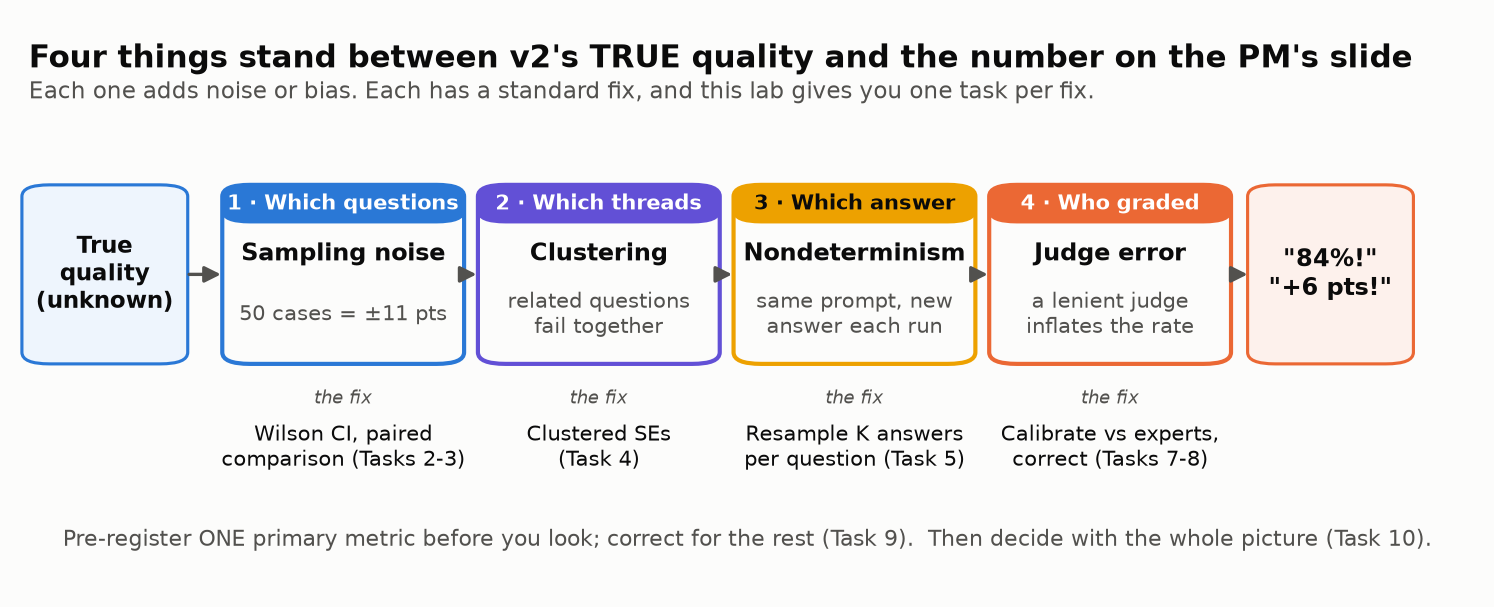

<sub>🖼️ *Four sources of noise and bias sit between v2's true quality and the number on the PM's slide. Each task in this lab measures one of them.*</sub>

## Overview

Teams compare prompt and model versions on small golden sets, and increasingly let an LLM judge grade production traffic. Both habits produce **numbers that look precise and aren't**. In this lab you take the PM's two headline numbers apart, one source of error at a time:

- **Part A: Is the 6-point gain real?** Sampling noise, paired comparisons, clustered questions, nondeterminism, and how many test cases you need (Tasks 1–6).
- **Part B: Can you trust the grader?** Calibrate the LLM judge against a tax professional's labels, then correct its pass rate for its errors (Tasks 7–8).
- **Part C: Decide.** Fake wins from many metrics and from peeking at running tests, then a SHIP / BLOCK verdict and an eval report card you can reuse at work (Tasks 9–10).

Everything runs offline on a seeded simulation, so **the true answer is known**; in Task 10 you check your estimates against it.

## Learning Objectives

You will be able to:

1. Put a **Wilson confidence interval** on a pass rate, and explain why ±11 points is normal for a 50-case golden set.
2. Compare two versions with a **paired** analysis (per-question differences, discordant pairs, McNemar test) instead of comparing two separate pass rates.
3. Compute **clustered standard errors** when test cases share a conversation, document, or customer.
4. Measure **nondeterminism** (same prompt, same questions, different scores) and reduce it by resampling answers.
5. Run a **sample-size (power) calculation** to size a golden set for the smallest change you care about.
6. Calibrate an LLM judge against expert labels with **TPR, TNR and Cohen's κ**, and explain why raw agreement misleads on imbalanced data.
7. **Correct a judge-reported pass rate** for judge error (Rogan-Gladen) with a bootstrap CI.
8. Control **multiple comparisons** (Holm) and **peeking**, and write an **eval report card** that supports a ship decision.

## Prerequisites

- Module 05 (LLM-as-judge, rubrics, meta-evaluation). Module 02's failure taxonomy helps.
- Comfortable with Python, `numpy` arrays and `pandas` DataFrames.
- **No statistics background required.** Each concept (standard error, confidence interval, power, κ) is explained in a 📐 **Key idea** box right before you use it.

## Estimated Time

**70–85 minutes** for the core lab. Challenges and stretch goals add 15–40 minutes.

| Part | Tasks | Time |
|---|---|---|
| Setup | Environment and Setup | 5 min |
| A. Is the gain real? | 1–6 | 35 min |
| B. Can you trust the grader? | 7–8 | 20 min |
| C. Decide | 9–10 | 18 min |

<details><summary>📖 Jargon decoder: 40 terms this lab uses (click to open)</summary>

| Term | Plain-English meaning | Where you'll meet it |
|---|---|---|
| **Golden set** | A fixed test set of questions with expert-graded answers, re-run on every version | Task 1 |
| **LLM judge** | A language model prompted to grade another model's answer PASS or FAIL | Tasks 1, 7–8 |
| **GA** (general availability) | Releasing to every customer, not a beta slice | Scenario |
| **Enrolled agent** ("the tax pro") | A federally licensed US tax professional; the ground truth in this lab | Scenario |
| **Point estimate** | One number (78%) with no error bar | Task 2 |
| **Standard error (SE)** | The typical size of an estimate's wobble from one sample of questions to the next | Task 2 |
| **Confidence interval (CI)**, **coverage** | A range from a recipe that captures the truth in 95% of repeated samples; that 95% is its coverage | Task 2 |
| **Wilson interval** | A CI for pass rates that stays honest at small n and near 0% or 100% | Task 2 |
| **Null** (null hypothesis) | The "nothing changed" world you test against | Task 2 |
| **p-value** | In the null world, the chance of a result at least this extreme. *Not* the chance the null is true | Task 3 |
| **Two-sided** | Counts extreme results in both directions (better *or* worse) | Task 3 |
| **Paired vs unpaired** | Comparing the same questions one by one vs comparing two separate pass rates | Task 3 |
| **Discordant pairs** (fixed / broke) | Questions whose PASS/FAIL outcome changed between versions | Task 3 |
| **McNemar test** | A coin-flip test on the fixed vs broke split | Tasks 3, 9 |
| **Correlation (r)** | How much two things move together, from −1 to 1; 0 = unrelated | Task 3 |
| **Standard deviation (SD)**, **variance**, `ddof=1` | Spread around the mean; variance = SD²; `ddof=1` divides by n − 1, the usual choice for a sample | Tasks 3, 6 |
| **Cluster**, **clustered SE** | A group of correlated cases (one conversation); an SE that sums within each group first | Task 4 |
| **Effective n** | How many independent cases a correlated set is really worth | Task 4 |
| **Bootstrap**, **with replacement** | Resample your data (repeats allowed), recompute, repeat; the middle 95% of results is the CI | Tasks 4, 8 |
| **Nondeterminism** | Same input, different output on different runs | Task 5 |
| **Resampling K answers** | Asking each question K times and averaging per question | Task 5 |
| **Power**, **α**, **β** | Power = chance of detecting a real change; α = false-alarm rate; β = miss rate = 1 − power | Task 6 |
| **δ**, **MDE** | The smallest change you care about; the smallest change your set can reliably detect | Task 6 |
| **z-cutoff** | Distance from the center of a bell curve in SEs; ±1.96 holds the middle 95% | Task 6 |
| **σ²**, **ω²** | Answer-to-answer randomness within a question; true variation of the gain between questions | Task 6 |
| **Positive class** | The label treated as "yes" (here PASS) | Task 7 |
| **Confusion matrix** (TP, FN, FP, TN) | The 2×2 table of judge vs expert verdicts | Task 7 |
| **TPR**, **TNR** | Share of good answers the judge passes; share of bad answers it catches | Task 7 |
| **Imbalanced labels** | One class dominates (here most answers pass) | Task 7 |
| **Cohen's κ** (kappa) | Agreement beyond what chance alone would produce; 0 = chance, 1 = perfect | Task 7 |
| **Rogan-Gladen correction** | Back-calculates the true pass rate from a judge's rate and its TPR/TNR | Task 8 |
| **Youden's J** | TPR + TNR − 1: the share of any real change that survives the judge | Task 8 |
| **Multiple comparisons**, **family-wise error rate** | Testing many metrics; the chance that at least one is a false alarm | Task 9 |
| **Bonferroni**, **Holm** | Corrections that scale p-values by the number of tests | Task 9 |
| **Pre-registration**, **exploratory** | Naming the primary metric before looking; everything else is a lead, not a win | Task 9 |
| **Non-inferiority** | Testing that v2 is not worse than v1 by more than a set margin | Task 10 |
| **Delta method** | Propagating small input errors through a formula using its derivatives | Challenge 3 |
| **Tax terms in the data** | *1099-NEC*: IRS form reporting payments to an independent contractor. *S-corp / K-1*: a corporation whose income passes through to its owners, each told their share on a Schedule K-1. *Section 179*: deduct equipment in the year you buy it. *Safe harbor*: estimated-tax payment levels that avoid an underpayment penalty. *QBI*: the qualified business income deduction for pass-through owners | Golden set (Task 1), optional judge section |
| **Structured output**, **pydantic** | Forcing a model's reply into a schema; pydantic declares that schema as a Python class | Optional judge section |
| **DROP, MGSM, RACE-H, HealthBench** | Public benchmarks cited in research cards: reading + arithmetic, multilingual grade-school math, exam reading comprehension, medical conversations | Research cards |

</details>


## Environment and Setup

1. Run the **imports** cell. Nothing to install: Colab has every package.
2. Run the **🎨 Lab kit** cell. It defines `insight()`, `tiles()`, `verdict()` and the chart theme. Its code is hidden; you don't need to read it.
3. Run the **🧰 Lab harness** cell. It builds the Brightbook simulator (golden set, re-runs, expert-labeled calibration set, 2,000 judge-graded production answers, the PM's dashboard) and holds the reference solutions behind your exercises. Peek if stuck, but try each exercise first.

> 💡 **Why a simulation?** In real life you never learn the true pass rate, only estimates. A seeded simulation gives the whole class identical numbers *and* lets you check your estimates against the truth at the end. Every technique here works unchanged on real data.

> 🎛️ **Interactive cells** (the slot machine in Task 9, the judge slider in Task 8) first draw a static default view, so *Run All* works anywhere; the buttons and sliders under it redraw live in Colab or Jupyter.

> 🧠 **How the exercises work:** each **🧠 Your Turn** cell holds a TODO; the ✅ check cell after it tests your function on three cases. If yours isn't finished or disagrees with the reference, the check says why and switches to the reference, so later tasks still run.


In [ ]:
# Everything below is preinstalled in Google Colab.
# Running locally? pip install numpy pandas scipy matplotlib
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 60)
print("✅ Environment ready")

In [ ]:
# @title 🎨 Lab kit: insight cards, stat tiles, chart theme (run me; no need to read)
# LABKIT v1 — shared across every lab in this course. Pure Python + IPython; no installs.
# Functions you'll see used in this notebook:
#   insight(headline, body, kind="insight")   -> a callout card that states what the numbers just revealed
#   tiles([(label, value, note, status), ...])  -> a row of KPI tiles (status: good|warning|serious|critical|None)
#   verdict(decision, reasons)                  -> a SHIP / SHIP WITH CAUTION / BLOCK banner
#   style_charts()                              -> one consistent matplotlib theme (called automatically)
#   PALETTE / STATUS                            -> the colors used in every chart
import html as _html

try:
    from IPython.display import HTML as _HTML, display as _display
except ImportError:  # running as a plain script
    _HTML, _display = None, None

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
_STATUS_ICON = {"good": "✅", "warning": "⚠️", "serious": "🟠", "critical": "⛔"}

_KINDS = {
    #  kind        icon  label                    accent     tint
    "insight":    ("💡", "Insight",               "#2a78d6", "#eef5fd"),
    "surprise":   ("🤯", "Counterintuitive",      "#6250d6", "#f1effc"),
    "warning":    ("⚠️", "Watch out",             "#ec835a", "#fdf1ec"),
    "production": ("🏭", "In production",         "#1baf7a", "#ebf8f3"),
    "numbers":    ("📈", "By the numbers",        "#eda100", "#fdf6e6"),
    "research":   ("📚", "What the research says", "#52514e", "#f3f2ef"),
}


def _show(markup):
    if _display is not None:
        _display(_HTML(markup))
    else:
        import re
        print(re.sub(r"<[^>]+>", "", markup))


def _md(text):
    """Tiny formatter: **bold**, `code`, and newlines. Everything else is escaped."""
    import re
    t = _html.escape(str(text))
    t = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", t)
    t = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", t)
    t = re.sub(r"`(.+?)`", r"<code style='background:#0000000d;padding:1px 4px;border-radius:4px'>\1</code>", t)
    return t.replace("\n", "<br>")


def insight(headline, body="", kind="insight"):
    """Render a callout card. Use it right after a result to say what the result *means*."""
    icon, label, accent, tint = _KINDS.get(kind, _KINDS["insight"])
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:12px 16px;margin:10px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {label}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:4px 0 6px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def tiles(items):
    """items: list of (label, value, note, status). status in good|warning|serious|critical|None."""
    cells = []
    for item in items:
        label, value, note, status = (list(item) + [None, None, None, None])[:4]
        color = STATUS.get(status, "#d9d8d4")
        icon = _STATUS_ICON.get(status, "")
        cells.append(
            f"<div style='flex:1 1 160px;min-width:150px;background:#fcfcfb;border:1px solid #e4e3df;"
            f"border-top:4px solid {color};border-radius:8px;padding:10px 14px'>"
            f"<div style='font-size:12px;color:#52514e'>{_md(label)}</div>"
            f"<div style='font-size:26px;font-weight:700;color:#0b0b0b;margin:2px 0'>{_md(value)}</div>"
            f"<div style='font-size:12px;color:#52514e'>{icon} {_md(note or '')}</div></div>"
        )
    _show(
        "<div style='display:flex;flex-wrap:wrap;gap:10px;margin:10px 0;"
        "font-family:system-ui,-apple-system,sans-serif;max-width:900px'>" + "".join(cells) + "</div>"
    )


def verdict(decision, reasons=()):
    """decision: 'SHIP' | 'SHIP WITH CAUTION' | 'BLOCK' (anything else renders neutral)."""
    d = str(decision).upper()
    status = "good" if d == "SHIP" else "critical" if d.startswith("BLOCK") else "warning"
    icon = {"good": "🚀", "critical": "🛑", "warning": "⚠️"}[status]
    items = "".join(f"<li>{_md(r)}</li>" for r in reasons)
    _show(
        f"<div style='border:2px solid {STATUS[status]};border-radius:10px;padding:12px 18px;margin:10px 0;"
        f"background:#fcfcfb;color:#0b0b0b;font-family:system-ui,-apple-system,sans-serif;max-width:900px'>"
        f"<div style='font-size:22px;font-weight:800'>{icon} {_html.escape(d)}</div>"
        f"<ul style='margin:6px 0 0 18px;padding:0;font-size:14px;line-height:1.5'>{items}</ul></div>"
    )


def style_charts():
    """One chart theme for the whole course: thin marks, recessive grid, fixed color order."""
    try:
        import matplotlib as mpl
        from cycler import cycler
    except ImportError:
        return
    mpl.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
        "axes.edgecolor": "#b9b8b3", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
        "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e9e8e4", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 11,
        "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
        "axes.prop_cycle": cycler(color=PALETTE), "figure.dpi": 110,
    })


style_charts()
print("🎨 Lab kit loaded: insight(), tiles(), verdict(), style_charts()")

In [ ]:
# @title 🧰 Lab harness: the Brightbook simulator + reference solutions (run me; code is hidden)
# ============================================================
# 🧰 LAB HARNESS — the "infrastructure" for this lab
# ============================================================
# This cell builds everything you'll USE but don't need to write:
#   1. golden       — the 50-case golden set the PM used (expert-graded v1 and v2 answers)
#   2. rerun_golden — re-ask the same 50 questions k more times (answers are random!)
#   3. draw_golden_sets — build many *new* 50-case golden sets from the same traffic
#   4. calib / prod — expert-vs-judge labels, and 2,000 judge-graded production answers
#   5. dashboard    — the PM's 10-metric scorecard
#   6. Helpers: bootstrap_corrected, simulate_null_dashboards, use_or_fallback, pct
#   7. Reference solutions (names start with _reference_) used as safety nets.
#      Peeking is allowed if you're stuck, but try the exercise first!
# Everything is simulated from fixed seeds, so the whole class sees the same numbers.
# Because it is a simulation, we also know the TRUTH (hidden in _TRUTH until Task 10).
# ============================================================
import math
import numpy as np
import pandas as pd
from scipy import stats

def _sig(x):
    return 1.0 / (1.0 + np.exp(-x))

# ---- 0. The latent world: each question has a difficulty; questions in one conversation share it ----
_SU, _SE, _SG = 1.3, 0.8, 0.5           # conversation effect, question effect, v2-vs-v1 per-question effect (logit SDs)
_A, _B, _B_NULL = 1.8517534857123885, 0.21638325191438196, 0.045578400982189834   # calibrated: v1 79%, v2 81% (null: v2 = v1)

def _latent(rng, n_conv, q=5):
    d = np.repeat(rng.normal(0, _SU, n_conv), q) + rng.normal(0, _SE, n_conv * q)
    g = rng.normal(0, _SG, n_conv * q)
    return d, g

# ---- 1. The golden set: 10 (anonymized) customer conversations x 5 follow-up questions -----------------
_CONVS = [
    ("C01", "Consulting S-corp, owner lives in NJ, works in NY", ["Do I file in both states?", "Is my NY income taxed twice?", "Which state gets my S-corp K-1 income?", "Do I need a NY nonresident return?", "Can I claim a credit for NY tax on my NJ return?"]),
    ("C02", "Freelance UX designer paid on 1099-NEC", ["Do I owe self-employment tax?", "Can I deduct my laptop?", "What is the 1099-NEC threshold?", "Can I deduct health insurance premiums?", "Should I pay quarterly estimates?"]),
    ("C03", "Rideshare + delivery driver, one car", ["Standard mileage or actual expenses?", "Can I switch methods this year?", "Are commuting miles deductible?", "Do tolls count on top of mileage?", "What records do I need for mileage?"]),
    ("C04", "Etsy candle shop selling in 30 states", ["Do I collect sales tax myself?", "What is a marketplace facilitator?", "Do I need a resale certificate for wax?", "Is shipping taxable?", "Do I file sales tax returns at all?"]),
    ("C05", "Food-truck LLC, single member", ["When are quarterly estimates due?", "How much should I pay each quarter?", "What is the safe-harbor rule?", "Is there a penalty for underpaying?", "Does my LLC file its own return?"]),
    ("C06", "Landscaping company hiring its first W-2 employee", ["What forms does a new hire fill out?", "How often do I deposit payroll taxes?", "What is FUTA?", "Do I need workers' comp?", "Contractor or employee for seasonal help?"]),
    ("C07", "Bakery that bought a $48k oven", ["Can I expense the oven this year?", "Section 179 or bonus depreciation?", "What if I sell the oven in 2 years?", "Does financing change the deduction?", "Is installation part of the cost basis?"]),
    ("C08", "Wedding photographer, side business", ["Is this a business or a hobby?", "Can I deduct a loss against my W-2 income?", "Can I deduct my camera gear?", "Do I need an EIN?", "Is my studio rent deductible?"]),
    ("C09", "Bookkeeping firm with 12 contractors", ["When are 1099-NECs due?", "Do I file 1099s electronically?", "Do I need W-9s on file?", "What if a contractor won't give a TIN?", "Are corporations exempt from 1099s?"]),
    ("C10", "Real-estate agent working from home", ["Can I take the home-office deduction?", "Simplified or regular method?", "Do I qualify for the QBI deduction?", "Is my car a business expense?", "Can I deduct MLS dues?"]),
]
_GOLD_P_V1 = [0.706, 0.31, 0.352, 0.535, 0.429, 0.841, 0.946, 0.961, 0.978, 0.855, 0.874, 0.669, 0.82, 0.906, 0.561,
              0.891, 0.908, 0.962, 0.967, 0.929, 0.974, 0.901, 0.891, 0.943, 0.937, 0.878, 0.905, 0.901, 0.914, 0.921,
              0.427, 0.668, 0.321, 0.585, 0.694, 0.888, 0.937, 0.922, 0.966, 0.936, 0.996, 0.946, 0.997, 0.991, 0.99,
              0.872, 0.915, 0.917, 0.934, 0.916]
_GOLD_P_V2 = [0.753, 0.264, 0.396, 0.593, 0.544, 0.76, 0.972, 0.933, 0.982, 0.867, 0.896, 0.716, 0.817, 0.837, 0.623,
              0.924, 0.96, 0.948, 0.986, 0.905, 0.983, 0.9, 0.933, 0.973, 0.947, 0.749, 0.953, 0.811, 0.923, 0.948,
              0.521, 0.739, 0.273, 0.621, 0.523, 0.908, 0.972, 0.943, 0.919, 0.949, 0.996, 0.96, 0.998, 0.988, 0.99,
              0.869, 0.823, 0.937, 0.959, 0.883]
_GOLD_V1 = "10000111100001111111111111111101001111111111111111"
_GOLD_V2 = "00010111111111111111111111111101000111111111111111"

golden = pd.DataFrame(
    [{"case_id": f"G-{5 * ci + qi + 1:02d}", "conversation": cid, "customer": who, "question": qs[qi]}
     for ci, (cid, who, qs) in enumerate(_CONVS) for qi in range(5)]
)
golden["v1_pass"] = [int(c) for c in _GOLD_V1]
golden["v2_pass"] = [int(c) for c in _GOLD_V2]
_P1, _P2 = np.array(_GOLD_P_V1), np.array(_GOLD_P_V2)


def rerun_golden(version, k=10, seed=0):
    """Re-ask the SAME 50 golden questions k more times with the SAME prompt + model, and have the
    tax pro grade each answer. Returns a (k, 50) array of 0/1. Answers vary run to run (nondeterminism)."""
    p = _P1 if version == "v1" else _P2
    rng = np.random.default_rng([505, seed, 1 if version == "v1" else 2])
    return (rng.random((k, len(p))) < p).astype(int)


def draw_golden_sets(n_sets=5000, null=True, seed=7):
    """Build n_sets brand-new 50-case golden sets (10 conversations x 5 questions) from the same traffic,
    answer each question once with v1 and once with v2, and return the observed pass rates.
    null=True simulates a world where v2 is EXACTLY as good as v1 on average."""
    rng = np.random.default_rng([505, seed])
    d, g = _latent(rng, 10 * n_sets)
    d, g = d.reshape(n_sets, 50), g.reshape(n_sets, 50)
    p1 = _sig(_A - d)
    p2 = _sig(_A - d + (_B_NULL if null else _B) + g)
    o1 = rng.random(p1.shape) < p1
    o2 = rng.random(p2.shape) < p2
    return pd.DataFrame({"v1_rate": o1.mean(1), "v2_rate": o2.mean(1)})


# ---- 2. Production traffic: 2,000 questions (400 conversations) answered by v2 -------------------
_rng = np.random.default_rng([505, 2022])
_d, _g = _latent(_rng, 400)
_PROD_P1, _PROD_P2 = _sig(_A - _d), _sig(_A - _d + _B + _g)
_prod_true = (_rng.random(2000) < _PROD_P2).astype(int)        # what a tax pro WOULD say (unknown in real life)
_JUDGE_TPR, _JUDGE_TNR = 0.97, 0.36                            # the judge's true behavior (unknown in real life)
_u = _rng.random(2000)
_prod_judge = np.where(_prod_true == 1, _u < _JUDGE_TPR, _u >= _JUDGE_TNR).astype(int)

prod = pd.DataFrame({"question_id": [f"P-{i + 1:04d}" for i in range(2000)],
                     "conversation": [f"PC{i // 5 + 1:03d}" for i in range(2000)],
                     "judge_pass": _prod_judge})

# A tax pro (an enrolled agent) labeled a random 200 of those answers; a 2nd pro double-labeled 60.
_cal_idx = np.arange(0, 2000, 10)
calib = pd.DataFrame({"question_id": prod["question_id"].values[_cal_idx],
                      "expert_pass": _prod_true[_cal_idx],
                      "judge_pass": _prod_judge[_cal_idx]})
_u2 = _rng.random(60)
_e1 = calib["expert_pass"].values[:60]
_e2 = np.where(_e1 == 1, _u2 >= 0.04, _u2 < 0.22).astype(int)
calib["expert2_pass"] = pd.array([*_e2, *([pd.NA] * 140)], dtype="Int64")

# ---- 3. The PM's 10-metric dashboard on the golden set (counts of discordant pairs) --------------
_rng_m = np.random.default_rng([505, 270])
_METRICS = ["correct (expert)", "cites the right IRS form", "asks for missing facts", "escalates when required",
            "plain language", "no SSN/EIN echoed back", "states the deadline", "includes disclaimer",
            "under 200 words", "friendly tone"]
_rows = [{"metric": _METRICS[0], "v1_pass": int(golden.v1_pass.sum()), "v2_pass": int(golden.v2_pass.sum()),
          "v2_fixed": int(((golden.v1_pass == 0) & (golden.v2_pass == 1)).sum()),
          "v2_broke": int(((golden.v1_pass == 1) & (golden.v2_pass == 0)).sum())}]
for m in _METRICS[1:]:
    base = _rng_m.uniform(0.6, 0.92)
    q = _sig(np.log(base / (1 - base)) + _rng_m.normal(0, 1.0, 50))
    a1, a2 = _rng_m.random(50) < q, _rng_m.random(50) < q          # SAME true rate for v1 and v2 (no real effect)
    _rows.append({"metric": m, "v1_pass": int(a1.sum()), "v2_pass": int(a2.sum()),
                  "v2_fixed": int((~a1 & a2).sum()), "v2_broke": int((a1 & ~a2).sum())})
dashboard = pd.DataFrame(_rows)

_TRUTH = {"v1_prod": float(_PROD_P1.mean()), "v2_prod": float(_PROD_P2.mean()),
          "judge_tpr": _JUDGE_TPR, "judge_tnr": _JUDGE_TNR,
          "v2_prod_sampled": float(_prod_true.mean())}


# ---- 4. Reference solutions (the safety nets) --------------------------------------------------
def _reference_paired_diff_ci(v1, v2, z=1.96):
    d = np.asarray(v2, float) - np.asarray(v1, float)
    se = d.std(ddof=1) / math.sqrt(len(d))
    return {"diff": d.mean(), "se": se, "lo": d.mean() - z * se, "hi": d.mean() + z * se}


def _reference_cases_needed(delta, var_per_question, alpha=0.05, power=0.80):
    z_a = stats.norm.ppf(1 - alpha / 2)
    z_b = stats.norm.ppf(power)
    return math.ceil((z_a + z_b) ** 2 * var_per_question / delta ** 2)


def _reference_judge_metrics(expert, judge):
    e, j = np.asarray(expert).astype(int), np.asarray(judge).astype(int)
    tp = int(((e == 1) & (j == 1)).sum()); fn = int(((e == 1) & (j == 0)).sum())
    tn = int(((e == 0) & (j == 0)).sum()); fp = int(((e == 0) & (j == 1)).sum())
    n = len(e)
    agree = (tp + tn) / n
    p_e = ((tp + fn) / n) * ((tp + fp) / n) + ((tn + fp) / n) * ((tn + fn) / n)
    kappa = (agree - p_e) / (1 - p_e) if p_e < 1 else 0.0
    return {"tp": tp, "fn": fn, "tn": tn, "fp": fp, "agreement": agree,
            "tpr": tp / (tp + fn) if tp + fn else float("nan"),
            "tnr": tn / (tn + fp) if tn + fp else float("nan"), "kappa": kappa}


def _reference_rogan_gladen(p_obs, tpr, tnr):
    j = tpr + tnr - 1
    if j <= 0:
        raise ValueError("Judge is no better than chance (TPR + TNR <= 1); correction is undefined.")
    return min(1.0, max(0.0, (p_obs + tnr - 1) / j))


def bootstrap_corrected(calib_expert, calib_judge, prod_judge, correct_fn, B=4000, seed=11):
    """Bootstrap CI for the corrected pass rate. Each round resamples BOTH the expert-labeled
    calibration set (uncertainty in TPR/TNR) and the judged production set (uncertainty in p_obs)."""
    rng = np.random.default_rng([505, seed])
    e, j = np.asarray(calib_expert).astype(int), np.asarray(calib_judge).astype(int)
    pj = np.asarray(prod_judge).astype(int)
    n_c, n_p = len(e), len(pj)
    out = []
    for _ in range(B):
        idx = rng.integers(0, n_c, n_c)
        eb, jb = e[idx], j[idx]
        tpr = jb[eb == 1].mean()
        tnr = 1 - jb[eb == 0].mean()
        p_obs = rng.binomial(n_p, pj.mean()) / n_p
        try:
            out.append(correct_fn(p_obs, tpr, tnr))
        except (ValueError, ZeroDivisionError):
            continue
    out = np.array(out)
    return {"lo": float(np.percentile(out, 2.5)), "hi": float(np.percentile(out, 97.5)), "draws": out}


def simulate_null_dashboards(n_dash=4000, n_metrics=10, alpha=0.05, seed=3):
    """Simulate n_dash dashboards in a world where v2 == v1 on EVERY metric (50 golden cases each).
    Returns the share of dashboards with at least one 'significant' metric, raw vs Holm-corrected."""
    rng = np.random.default_rng([505, seed])
    base = rng.uniform(0.6, 0.92, (n_dash, n_metrics, 1))
    q = _sig(np.log(base / (1 - base)) + rng.normal(0, 1.0, (n_dash, n_metrics, 50)))
    a1, a2 = rng.random(q.shape) < q, rng.random(q.shape) < q
    fixed, broke = (~a1 & a2).sum(-1), (a1 & ~a2).sum(-1)
    n = fixed + broke
    p = np.where(n == 0, 1.0, np.minimum(1.0, 2 * stats.binom.cdf(np.minimum(fixed, broke), np.maximum(n, 1), 0.5)))
    raw_any = (p < alpha).any(1).mean()
    holm_any = (p.min(1) * n_metrics < alpha).mean()        # Holm's first step = Bonferroni on the smallest p
    return {"raw_any": float(raw_any), "holm_any": float(holm_any), "per_test": float((p < alpha).mean())}


def _close(got, want):
    if isinstance(want, dict):
        return isinstance(got, dict) and all(k in got and _close(got[k], want[k]) for k in want)
    return bool(np.isclose(float(got), float(want), rtol=1e-6, atol=1e-9))


def _fmt(x):
    try:
        return f"{float(x):.4g}"
    except (TypeError, ValueError):
        return repr(x)[:60]


def _diff(got, want):
    if isinstance(want, dict):
        if not isinstance(got, dict):
            return f"expected a dict with keys {list(want)}, got {type(got).__name__}"
        for k in want:
            if k not in got:
                return f"missing key '{k}'"
            if not _close(got[k], want[k]):
                return f"'{k}' should be {_fmt(want[k])}, got {_fmt(got[k])}"
    return f"expected {_fmt(want)}, got {_fmt(got)}"


def use_or_fallback(label, yours, reference, cases):
    """Safety net for the 🧠 exercises: test YOUR function against the reference on a few cases.
    If it isn't finished (or disagrees), keep going with the reference so Run All still works."""
    try:
        for i, args in enumerate(cases, start=1):
            got, want = yours(*args), reference(*args)
            if not _close(got, want):
                raise AssertionError(f"test case {i}: {_diff(got, want)}")
        print(f"✅ Exercise {label}: your function matches the reference on {len(cases)} test cases. Using YOUR version.")
        return yours
    except NotImplementedError:
        print(f"📝 Exercise {label} is not done yet, so the reference solution is used and Run All keeps working.")
    except Exception as e:  # noqa: BLE001  (show any learner error, then fall back)
        print(f"❌ Exercise {label}: {type(e).__name__}: {e}\n   → Using the reference solution for now. Fix yours and re-run this cell.")
    return reference


def pct(x, digits=0):
    return f"{100 * x:.{digits}f}%"


print(f"🧰 Harness loaded: golden set ({len(golden)} cases, {golden.conversation.nunique()} conversations), "
      f"calibration set ({len(calib)} expert labels), production run ({len(prod):,} judged answers), "
      f"{len(dashboard)}-metric dashboard.")

#### Checkpoint
Three cells ran without errors and you see the three confirmation lines below.

#### Expected Output
```
✅ Environment ready
🎨 Lab kit loaded: insight(), tiles(), verdict(), style_charts()
🧰 Harness loaded: golden set (50 cases, 10 conversations), calibration set (200 expert labels), production run (2,000 judged answers), 10-metric dashboard.
```

## Scenario

**Brightbook** (fictional) sells accounting and tax software to small businesses. Its AI **tax-help assistant** answers questions like *"Can I expense my $48k oven this year?"* inside the product. Prompt **v1** runs in a limited beta; prompt **v2** now answers 5% of beta traffic. The PM wants v2 for every customer (general availability, "GA") before filing season.

A wrong tax answer costs the customer penalties and interest, and costs Brightbook trust, so Brightbook has a written launch policy:

| Brightbook AI launch policy (fictional) | |
|---|---|
| **Primary metric** | Expert-graded correctness. An **enrolled agent** (a federally licensed tax professional, "the tax pro" below) marks each answer PASS or FAIL. |
| **GA bar** | At least **85%** of production answers correct. |
| **Improvement claims** | A claimed gain needs a 95% confidence interval that excludes zero. |

**The evidence on your desk:**

| Artifact | What it is | In the harness |
|---|---|---|
| Golden set (a fixed, expert-graded test set) | 50 questions from 10 anonymized customer conversations (5 follow-ups each), answered by v1 and v2, graded by the tax pro | `golden` |
| Judge dashboard | An LLM judge (a model prompted to grade answers PASS/FAIL) graded 2,000 production answers from v2 | `prod` |
| Calibration set | The tax pro also graded 200 of those 2,000 answers; a second tax pro double-graded 60 | `calib` |
| PM's scorecard | v1 vs v2 on 10 metrics over the golden set | `dashboard` |

**Your role:** the eval engineer who signs off. Your answer must survive a skeptical VP *and* a compliance reviewer.

---

## Tasks

# Part A: Is the 6-point gain real?

### Task 1: The PM's Claim

#### Goal
See the evidence the PM saw, and commit to a call **before** you analyze it.

#### Steps
1. 🔮 **Predict:** based only on "78% → 84% on 50 cases" and "judge says 90%", would you ship v2 to everyone? Write it down in the cell below the code.
2. Run the cell. Look at a few golden-set rows and the four tiles.

In [ ]:
LAUNCH_BAR = 0.85                     # Brightbook GA policy: >= 85% expert-graded correctness

n = len(golden)
k1, k2 = int(golden.v1_pass.sum()), int(golden.v2_pass.sum())
r1, r2 = k1 / n, k2 / n
gain = r2 - r1
judge_rate = prod.judge_pass.mean()

display(golden.head(6))
tiles([
    ("v1 pass rate (golden set)", pct(r1), f"{k1} of {n} questions", None),
    ("v2 pass rate (golden set)", pct(r2), f"{k2} of {n} questions", None),
    ("Claimed gain", f"+{100 * gain:.0f} pts", "the PM's headline", "warning"),
    ("Judge says (production)", pct(judge_rate, 1), f"GA bar is {pct(LAUNCH_BAR)}",
     "good" if judge_rate >= LAUNCH_BAR else "critical"),
])
insight(
    f"The whole +{100 * gain:.0f}-point headline is {k2 - k1} questions",
    f"On a {n}-case golden set every question is worth {100 / n:.0f} points: v2 passed {k2}, v1 passed {k1}. "
    "Before you trust any headline, translate it back into **how many test cases changed**.",
    kind="numbers",
)

#### ✍️ Your call (before any analysis)

**Decision:** `SHIP / SHIP WITH CAUTION / BLOCK`

**How confident are you (0–100%)?**

**What evidence would change your mind?**

> Write it here. You'll revisit it in Task 10.

#### Checkpoint
You see a table of 6 golden-set rows (case, conversation, customer, question, `v1_pass`, `v2_pass`) and four tiles.

#### Expected Output
Tiles: **78%** (39 of 50), **84%** (42 of 50), **+6 pts**, and **90.1%** judge-reported (green, above the 85% bar).
📈 card: *"The whole +6-point headline is 3 questions."*

#### 🔮 Lock in five numbers

The lab's biggest surprises, as numbers. Overwrite the defaults with your own guesses and run the cell; **Key Takeaways scores them**. It prints `🔒 Locked in 5 predictions. Key Takeaways will score them.`


In [ ]:
# 🔮 YOUR PREDICTIONS: overwrite these plausible-sounding defaults with your own guesses, then run.
MY_PREDICTIONS = {
    "rerun_swing_pts": 4,             # Task 5: re-run the SAME v2 10 times; best minus worst pass rate, in points
    "questions_for_3pt_gain": 300,    # Task 6: paired questions needed to detect a real 3-point gain (80% power)
    "judge_catches_pct": 80,          # Task 7: % of the tax pro's FAILs that the LLM judge also FAILs
    "true_pass_rate_pct": 90,         # Task 8: v2's real production pass rate (the judge says 90%; the bar is 85%)
    "peeking_false_alarm_pct": 5,     # Task 9: % of no-difference tests called 'different' if checked daily for 20 days
}
print(f"🔒 Locked in {len(MY_PREDICTIONS)} predictions. Key Takeaways will score them.")


**Bridge:** 3 questions out of 50 is not many. How big a swing does pure chance produce on a set this small?

### Task 2: How Noisy Is a 50-Case Score?

#### Goal
Put an error bar on each pass rate, then see how often pure chance produces a 6-point "win".

> 📐 **Key idea: a pass rate is an estimate.** The 78% is a **point estimate**: one number, no error bar. Your 50 questions are a *sample* of everything customers will ask; a different 50 would give a different pass rate. The **standard error (SE)** is the typical size of that wobble: for a pass rate *p* on *n* questions, SE = √(p(1−p)/n). For v1, √(0.78·0.22/50) ≈ 0.059, about 6 points.
>
> A **95% confidence interval (CI)** is roughly the estimate ± 2 SE. The 95% is a promise about the recipe, not about this one interval: across many golden sets, 95% of intervals built this way contain the true rate (their **coverage**). It covers *sampling* noise only, which questions you happened to draw; a biased grader (Part B) is not inside it.
>
> For small *n* or rates near 0% or 100%, use the **Wilson interval** instead of p ± 1.96·SE: it stays inside 0–100%, its coverage is closer to the promised 95%, and it is asymmetric near the edges (watch v2's). Why it's needed: the textbook interval plugs the observed rate into the SE, so a perfect 50/50 gets SE = 0 and claims "100% to 100%". Wilson instead asks *which true rates would make this result unsurprising*; the first cell shows its answer for 50/50.

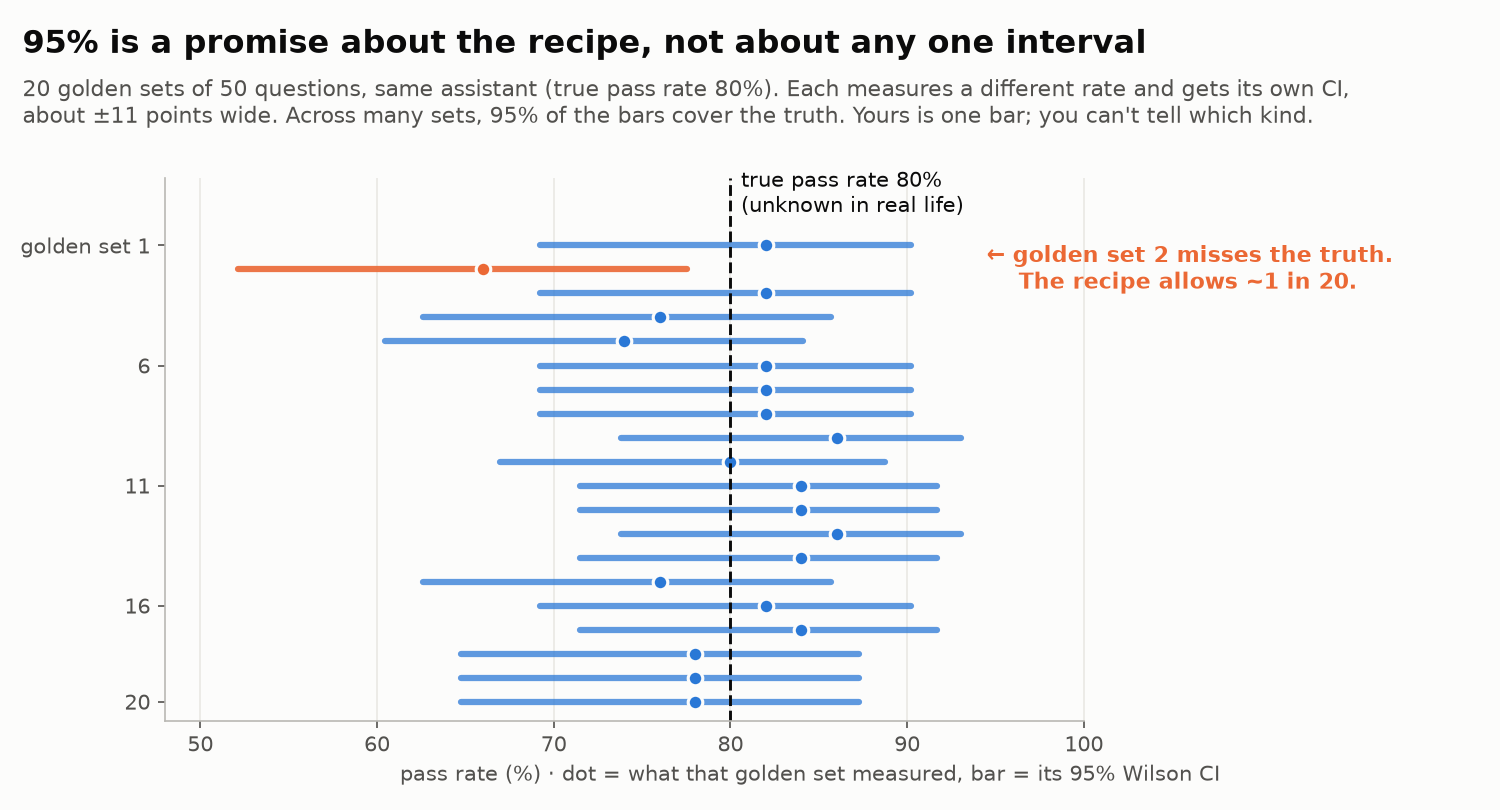

<sub>🖼️ *What "95%" means: twenty golden sets from the same assistant, twenty different intervals, one miss. You never know whether yours is the miss.*</sub>

#### Steps
1. Run the first cell: Wilson CIs for v1 and v2.
2. 🔮 **Predict:** imagine v2 is **exactly as good** as v1 (statisticians call this the **null**: no real difference). If you built a fresh 50-case golden set from the same kind of conversations and graded one answer per version, how often would v2 still "win" by 6 or more points? **(a) <1% (b) ~5% (c) ~25% (d) ~50%**
3. Run the second cell. It builds 5,000 fresh golden sets in that null world.


In [ ]:
def wilson_ci(k, n, z=1.96):
    """95% Wilson score interval for k passes out of n."""
    p = k / n
    center = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return max(0.0, center - half), min(1.0, center + half)


ci1, ci2 = wilson_ci(k1, n), wilson_ci(k2, n)
print(f"v1: {pct(r1)}   95% CI {pct(ci1[0], 1)} to {pct(ci1[1], 1)}")
print(f"v2: {pct(r2)}   95% CI {pct(ci2[0], 1)} to {pct(ci2[1], 1)}")
print(f"The two intervals overlap by {100 * (ci1[1] - ci2[0]):.1f} points.")
lo_p, hi_p = wilson_ci(50, 50)
print(f"A perfect 50/50: textbook CI 100.0% to 100.0%; Wilson {pct(lo_p, 1)} to {pct(hi_p, 1)}")

In [ ]:
sims = draw_golden_sets(n_sets=5000, null=True)        # a world where v2 is EXACTLY as good as v1
null_gap = (sims.v2_rate - sims.v1_rate).round(2)
p_fake_win = (null_gap >= round(gain, 2)).mean()        # v2 "wins" by >= the PM's gain
p_any_gap = (null_gap.abs() >= round(gain, 2)).mean()   # a gap that big in either direction
v1_lo, v1_hi = np.percentile(sims.v1_rate, [2.5, 97.5])

fig, ax = plt.subplots(figsize=(8.5, 3.6))
bins = np.arange(-0.31, 0.32, 0.02)
ax.hist(null_gap, bins=bins, color=PALETTE[0], alpha=0.85, edgecolor="#fcfcfb", label="v2 no better")
ax.hist(null_gap[null_gap >= round(gain, 2)], bins=bins, color=PALETTE[1], edgecolor="#fcfcfb",
        label=f"looks like a ≥{100 * gain:.0f}-pt win")
ax.axvline(gain, color="#0b0b0b", lw=1.2, ls="--")
ax.annotate(f"PM's +{100 * gain:.0f} pts", (gain, ax.get_ylim()[1] * 0.92), xytext=(6, 0),
            textcoords="offset points", fontsize=10, color="#0b0b0b")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{100 * x:+.0f}" if abs(x) > 1e-9 else "0"))
ax.set_axisbelow(True)
ax.set_xlabel("v2 − v1 on a freshly built 50-case golden set (points)")
ax.set_ylabel("golden sets (of 5,000)")
ax.set_title(f"v2 no better, yet {pct(p_fake_win)} of golden sets show a ≥{100 * gain:.0f}-pt 'win'")
ax.legend(loc="upper left")
plt.show()

insight(
    f"If v2 changed nothing, {pct(p_fake_win)} of 50-case golden sets would still show it winning by {100 * gain:.0f}+ points",
    f"A gap of {100 * gain:.0f}+ points in *either* direction shows up {pct(p_any_gap)} of the time. Even v1's own score "
    f"ranges from {pct(v1_lo)} to {pct(v1_hi)} (middle 95%) across golden sets, with the same prompt and the same model. "
    f"Rule of thumb: **on 50 cases a single pass rate is about ±{100 * (ci1[1] - ci1[0]) / 2:.0f} points; "
    "never report one without its interval.**",
    kind="surprise",
)
insight(
    "Report every eval score with a standard error (Miller, 2024)",
    "Anthropic's *Adding Error Bars to Evals* (Miller, arXiv 2411.00640, Nov 2024) recommends a standard error on every "
    "eval score, clustered SEs for grouped questions, resampling answers, paired comparisons, and power analysis: the "
    "rest of Part A. A 50-item eval at 80% accuracy has SE ≈ 5.7 points, a 95% CI of about ±11 points; "
    "100 items still gives about ±7.8.",
    kind="research",
)

#### Checkpoint
Two printed CIs that overlap heavily, a histogram centered on zero with an orange right tail, and two cards.

#### Expected Output
```
v1: 78%   95% CI 64.8% to 87.2%
v2: 84%   95% CI 71.5% to 91.7%
The two intervals overlap by 15.8 points.
A perfect 50/50: textbook CI 100.0% to 100.0%; Wilson 92.9% to 100.0%
```
The last line is worth memorizing: **zero failures in 50 tests is still consistent with a 7% failure rate.** (Challenge 1 asks how many clean tests a "< 1%" claim needs.)
Chart title: *"v2 no better, yet 24% of golden sets show a ≥6-pt 'win'"*.
🤯 card: *"If v2 changed nothing, 24% of 50-case golden sets would still show it winning by 6+ points"* (a 6+ point gap in either direction: 48%; v1 alone ranges 62% to 92%; ±11 points).

> ⚠️ **Overlapping intervals are not a test.** Two CIs can overlap while the difference between them is real, because the right comparison is on the *paired* differences. That's Task 3.

**Bridge:** the PM's comparison has one thing going for it: both versions answered **the same 50 questions**. Use that.

### Task 3: Compare the Same Questions (Paired Analysis)

#### Goal
Measure the gain from **per-question differences**, count the questions whose outcome changed, and test whether that count beats chance.

> 📐 **Key idea: pair your comparison.** Hard questions are hard for *both* versions. An **unpaired** comparison (two separate pass rates, as in Task 2) treats v1's 50 answers and v2's 50 as unrelated samples, so that shared difficulty inflates the noise. A **paired** comparison takes each question's difference d = v2 − v1 (+1, 0 or −1); the shared difficulty cancels. SE of the mean difference = std(d) / √n. How much this helps depends on the **correlation** *r* between v1's and v2's outcomes (−1 to 1; 0 = unrelated): the higher *r*, the more shared noise cancels.
>
> Only questions whose outcome **changed** carry information: the **discordant pairs**, "v2 fixed" (v1 FAIL → v2 PASS) and "v2 broke" (v1 PASS → v2 FAIL). The **McNemar test** treats each changed question as a coin flip (if v2 were no better, "fixed" and "broke" are equally likely) and asks how surprising the observed split is: 5 fixed vs 2 broke is 5 heads in 7 flips.
>
> Its **p-value** is the probability, if v2 were no better, of a split at least this lopsided in either direction (**two-sided**). Below 0.05, by convention, reads as "unlikely to be chance". It is *not* the probability that v2 is better.

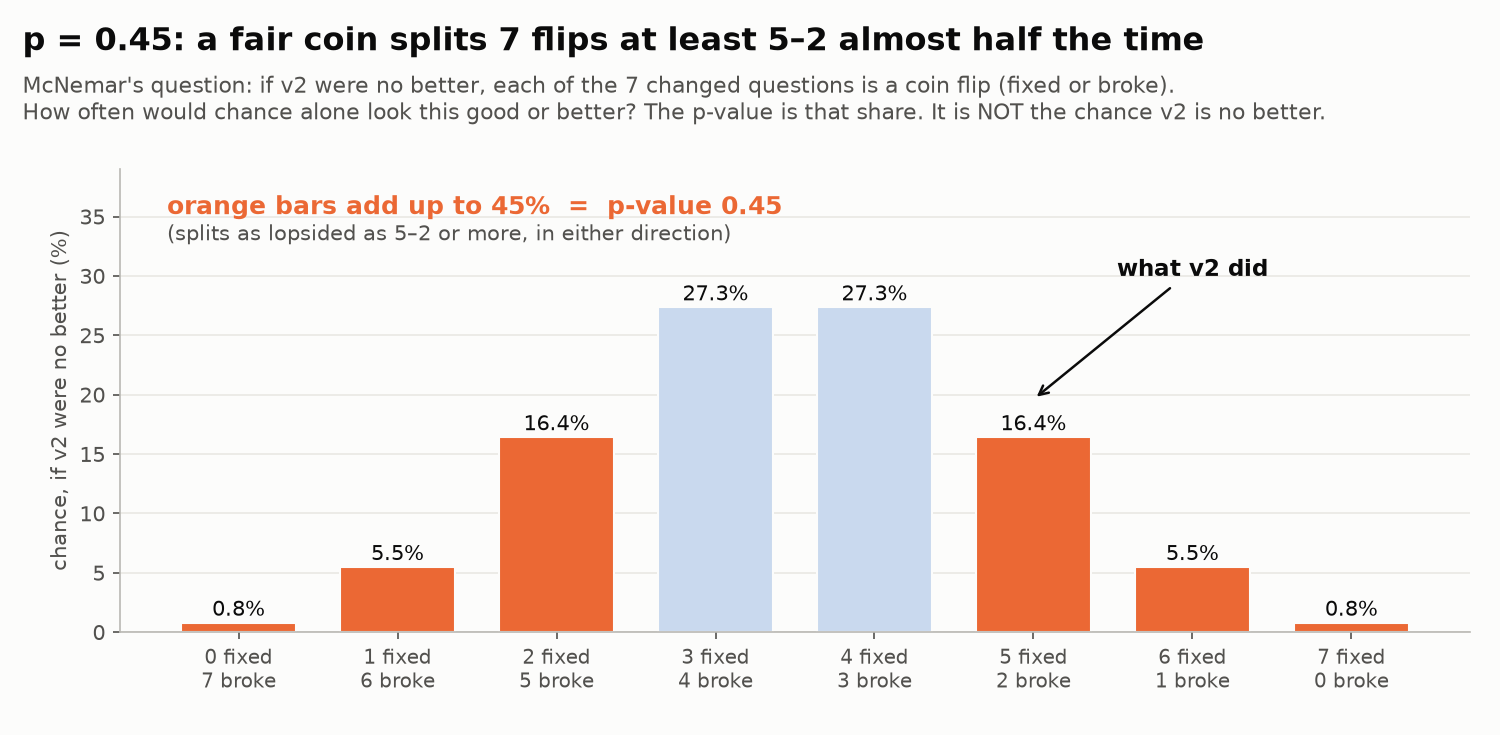

<sub>🖼️ *The p-value, drawn: if v2 were no better, 45% of coin-flip worlds look at least as good as "5 fixed, 2 broke".*</sub>

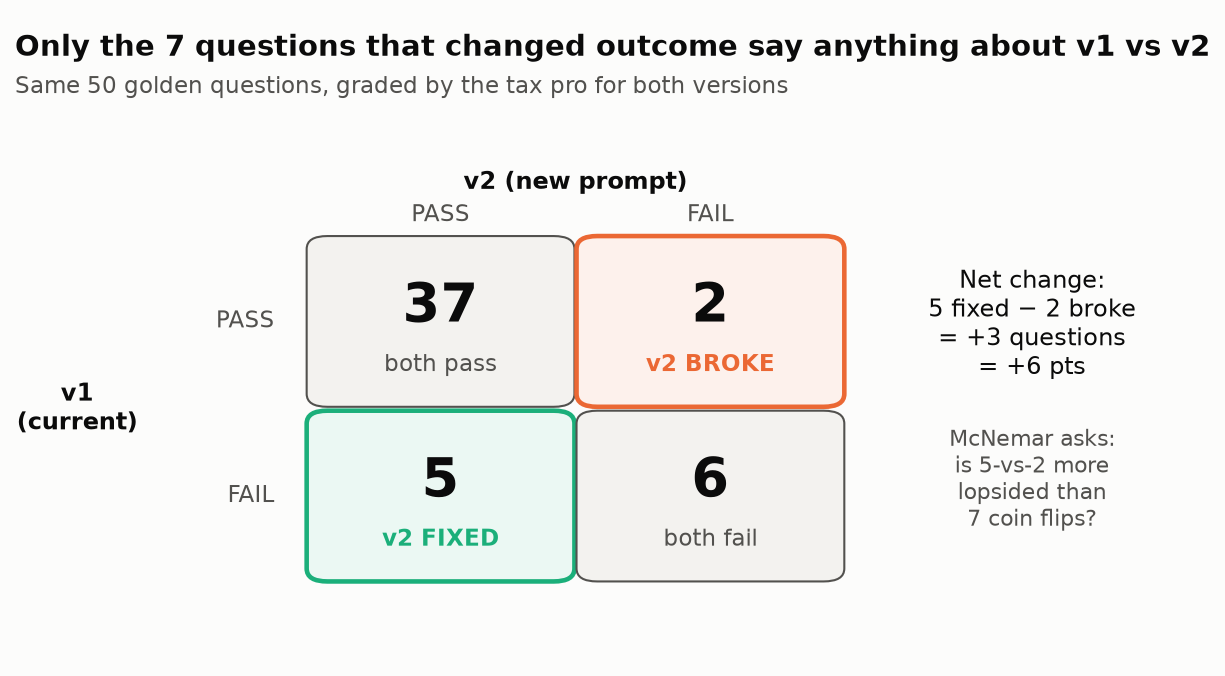

<sub>🖼️ *Only the 7 discordant questions say anything about v1 vs v2. Your run will reproduce these counts.*</sub>

#### Steps
1. 🔮 **Predict:** will pairing make the CI on the +6 narrower, wider, or the same? Will it exclude zero?
2. **🧠 Exercise 3A:** complete `paired_diff_ci` (about 4 lines). Then run the ✅ check cell.
3. Run the analysis cell.

<details><summary>💡 Hint 1</summary>

`d = np.asarray(v2, float) - np.asarray(v1, float)` gives one number per question: +1, 0 or −1.
</details>

<details><summary>💡 Hint 2</summary>

Use the **sample** standard deviation: `d.std(ddof=1)` divides by n − 1, not n, because the mean was estimated from the same data. Divide by `math.sqrt(len(d))` for the SE.
</details>

<details><summary>✅ Full solution</summary>

```python
def paired_diff_ci(v1, v2, z=1.96):
    d = np.asarray(v2, float) - np.asarray(v1, float)
    diff = d.mean()
    se = d.std(ddof=1) / math.sqrt(len(d))
    return {"diff": diff, "se": se, "lo": diff - z * se, "hi": diff + z * se}
```
</details>

In [ ]:
# 🧠 YOUR TURN — Exercise 3A: the paired difference and its 95% CI
def paired_diff_ci(v1, v2, z=1.96):
    """v1, v2: 0/1 outcomes on the SAME questions, in the same order.
    Returns {"diff", "se", "lo", "hi"} for the mean of (v2 - v1)."""
    # TODO: one difference per question (v2 - v1), then the mean difference, its standard error and the
    #       95% CI (mean ± z·SE). Which standard deviation (ddof) belongs in an SE? The 📐 box and hints help.
    raise NotImplementedError("Exercise 3A")

In [ ]:
# ✅ CHECK 3A
paired_diff_ci = use_or_fallback(
    "3A", paired_diff_ci, _reference_paired_diff_ci,
    cases=[(golden.v1_pass, golden.v2_pass), ([1, 1, 0, 0, 1], [1, 0, 1, 1, 1]), ([0] * 10, [1] * 4 + [0] * 6)],
)

In [ ]:
def mcnemar_exact_p(fixed, broke):
    """Exact two-sided McNemar test: if v2 were no better, each changed question is a fair coin flip."""
    m = fixed + broke
    return 1.0 if m == 0 else float(min(1.0, 2 * stats.binom.cdf(min(fixed, broke), m, 0.5)))


fixed = int(((golden.v1_pass == 0) & (golden.v2_pass == 1)).sum())
broke = int(((golden.v1_pass == 1) & (golden.v2_pass == 0)).sum())
p_mcnemar = mcnemar_exact_p(fixed, broke)

se_unpaired = math.sqrt(r1 * (1 - r1) / n + r2 * (1 - r2) / n)   # treats v1 and v2 as unrelated samples
unpaired = {"diff": gain, "se": se_unpaired, "lo": gain - 1.96 * se_unpaired, "hi": gain + 1.96 * se_unpaired}
paired = paired_diff_ci(golden.v1_pass, golden.v2_pass)
corr = np.corrcoef(golden.v1_pass, golden.v2_pass)[0, 1]
shrink = 1 - paired["se"] / unpaired["se"]
data_equiv = (unpaired["se"] / paired["se"]) ** 2

tiles([
    ("v2 fixed", fixed, "v1 FAIL → v2 PASS", None),
    ("v2 broke", broke, "v1 PASS → v2 FAIL", None),
    ("McNemar p-value", f"{p_mcnemar:.2f}", "≥ 0.05: could easily be chance", "warning" if p_mcnemar >= 0.05 else "good"),
    ("v1/v2 outcome correlation", f"{corr:.2f}", "hard questions are hard for both", None),
])

fig, ax = plt.subplots(figsize=(8.5, 2.6))
for y, (label, res, color) in enumerate([("Unpaired (two separate rates)", unpaired, PALETTE[6]),
                                         ("Paired (per-question differences)", paired, PALETTE[0])]):
    ax.plot([100 * res["lo"], 100 * res["hi"]], [y, y], color=color, lw=3, solid_capstyle="round")
    ax.plot(100 * res["diff"], y, "o", color=color, markersize=9, markeredgecolor="#fcfcfb", markeredgewidth=2)
    ax.annotate(f"{100 * res['lo']:+.1f} to {100 * res['hi']:+.1f} pts", (100 * res["hi"], y), xytext=(8, -4),
                textcoords="offset points", fontsize=10, color="#52514e")
ax.axvline(0, color="#0b0b0b", lw=1, ls="--")
ax.set_yticks([0, 1], ["Unpaired (two separate rates)", "Paired (per-question differences)"])
ax.set_ylim(-0.6, 1.6)
ax.set_xlim(-15, 32)
ax.set_xlabel("v2 − v1 (points), dot = estimate, bar = 95% CI")
ax.set_title(f"Pairing shrinks the error bar by {shrink:.0%}, but zero is still inside")
ax.grid(axis="y", visible=False)
plt.show()

insight(
    f"v2 fixed {fixed} questions and broke {broke}: the +{100 * gain:.0f} rests on {fixed + broke} coin flips "
    f"(McNemar p = {p_mcnemar:.2f})",
    f"Pairing cut the standard error by {shrink:.0%}: v1 and v2 outcomes correlate at r = {corr:.2f} (hard questions "
    f"are hard for both), and pairing cancels that shared difficulty, worth **{data_equiv:.1f}× more questions** for "
    f"free. Yet the paired 95% CI is still {100 * paired['lo']:+.1f} to {100 * paired['hi']:+.1f} points. "
    "Rule of thumb: **compare versions on the same questions and report the paired CI and the fixed/broke counts, "
    "never two separate pass rates.**",
)

#### Checkpoint
Your ✅ check passes (or the 📝 fallback message appears), four tiles, a two-row interval chart, and an insight card.

#### Expected Output
```
✅ Exercise 3A: your function matches the reference on 3 test cases. Using YOUR version.
```
(Before you finish the exercise you'll see `📝 Exercise 3A is not done yet, so the reference solution is used...` instead. Every number below is the same either way.)

Tiles: **5** fixed, **2** broke, McNemar p **0.45**, correlation **0.56**. Unpaired CI **−9.3 to +21.3** pts; paired CI **−4.3 to +16.3** pts.
💡 card: *"v2 fixed 5 questions and broke 2: the +6 rests on 7 coin flips (McNemar p = 0.45)"*: pairing cut the SE by **33%**, worth **2.2×** more questions.

**Bridge:** the paired SE assumes the 50 questions are 50 independent pieces of evidence. They aren't: they come from 10 conversations.

### Task 4: Questions Come in Clusters

#### Goal
Measure how much the golden set's conversation structure widens the error bars, and find **which conversations** drive v2's gain.

> 📐 **Key idea: clustered standard errors.** The golden set is 10 conversations × 5 follow-up questions. If the assistant misreads "S-corp owner who lives in NJ and works in NY" in turn 1, the five follow-ups tend to fail **together**, so they carry less information than five questions from five customers. The **naive SE** (Task 3) treats all 50 as independent.
>
> A **clustered SE** sums the residuals (value − mean) *within each conversation first*, then squares, so correlated questions can't pose as independent evidence. Two numbers fall out: **SE inflation** = clustered SE ÷ naive SE (how overconfident the naive interval was) and **effective n** = n ÷ inflation² (how many independent questions your set is really worth). A **bootstrap** gets an interval by brute force instead of a formula: resample your data **with replacement** (each draw may pick the same item again or skip one), recompute the statistic, repeat thousands of times, and keep the middle 95% of the results. A **cluster bootstrap** resamples whole conversations, so related questions travel together (Stretch B asks you to code it).

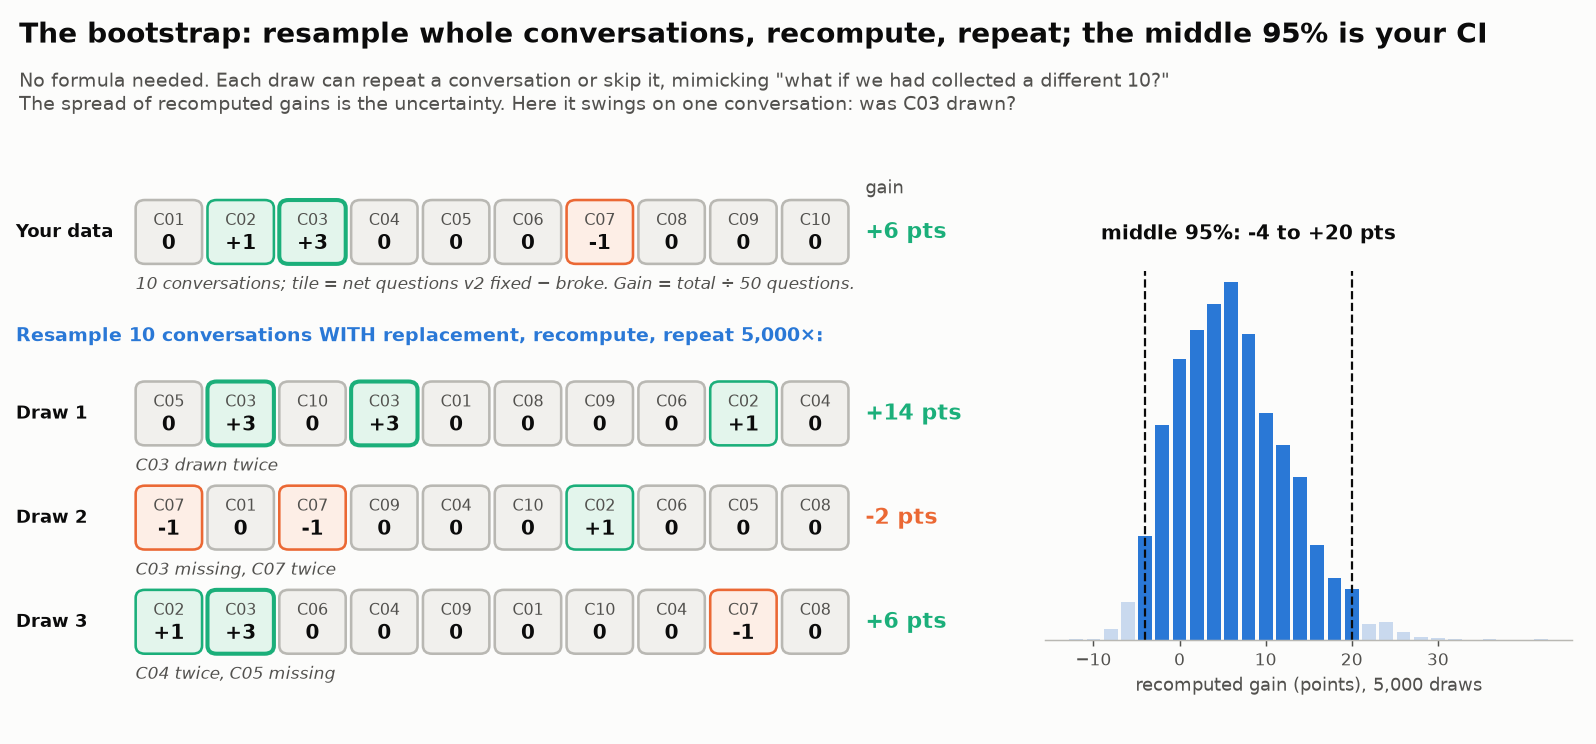

<sub>🖼️ *Cluster bootstrap on this lab's golden set. Whether C03 lands in the draw decides most of the answer, which is the clustering problem in one picture.*</sub>

#### Steps
1. 🔮 **Predict:** how many *independent* questions are your 50 worth? **50 / 35 / 12?**
2. Run the cell.


In [ ]:
def clustered_se(x, clusters):
    """Clustered SE of a mean: sum residuals WITHIN each cluster first, then square. G/(G-1) corrects for few clusters."""
    x = np.asarray(x, float)
    sums = pd.Series(x - x.mean()).groupby(np.asarray(clusters)).sum().values
    G = len(sums)
    return math.sqrt(G / (G - 1) * (sums**2).sum()) / len(x)


conv = golden.conversation
d = golden.v2_pass - golden.v1_pass
naive_v2 = golden.v2_pass.std(ddof=1) / math.sqrt(n)
clust_v2 = clustered_se(golden.v2_pass, conv)
ratio_v2 = clust_v2 / naive_v2
n_eff = n / ratio_v2**2
clust_d = clustered_se(d, conv)
paired_cl = {"diff": d.mean(), "se": clust_d, "lo": d.mean() - 1.96 * clust_d, "hi": d.mean() + 1.96 * clust_d}

by_conv = (golden.assign(net=d)
           .groupby(["conversation", "customer"], as_index=False)
           .agg(net_change=("net", "sum"), v2_fails=("v2_pass", lambda s: int((s == 0).sum()))))
top = by_conv.loc[by_conv.net_change.idxmax()]
share_top = top.net_change / d.sum()

tiles([
    ("v2 95% CI, naive", f"±{196 * naive_v2:.0f} pts", "treats 50 questions as independent", None),
    ("v2 95% CI, clustered", f"±{196 * clust_v2:.0f} pts", "10 conversations × 5 questions", "warning"),
    ("SE inflation", f"{ratio_v2:.1f}×", "clustered ÷ naive", "warning"),
    ("Effective n", f"≈ {n_eff:.0f}", f"of {n} questions", "serious"),
])

fig, ax = plt.subplots(figsize=(8.5, 3.4))
colors = [PALETTE[2] if v > 0 else PALETTE[1] if v < 0 else "#b9b8b3" for v in by_conv.net_change]
ax.bar(by_conv.conversation, by_conv.net_change, color=colors, width=0.6)
ax.axhline(0, color="#0b0b0b", lw=0.8)
ax.set_axisbelow(True)
for i, v in enumerate(by_conv.net_change):
    if v:
        ax.annotate(f"{v:+d}", (i, v), xytext=(0, 4 if v > 0 else -14), textcoords="offset points",
                    ha="center", fontsize=10, color="#0b0b0b")
ax.set_ylabel("net questions (fixed − broke)")
ax.set_ylim(-1.8, by_conv.net_change.max() + 1)
ax.set_title(f"{share_top:.0%} of v2's net gain comes from one conversation ({top.conversation})")
plt.show()

insight(
    f"Your {n} golden questions behave like about {n_eff:.0f} independent ones",
    f"Clustering by conversation makes v2's standard error {ratio_v2:.1f}× larger: its 95% CI is "
    f"±{196 * clust_v2:.0f} points, not ±{196 * naive_v2:.0f}. The paired gain's clustered CI widens to "
    f"{100 * paired_cl['lo']:+.1f} to {100 * paired_cl['hi']:+.1f} points. And {share_top:.0%} of the net gain comes from "
    f"the 5 questions of {top.conversation} (*{top.customer}*); every other conversation nets to zero. "
    "Rule of thumb: **when cases share a conversation, document or customer, cluster your SEs (or bootstrap whole "
    "clusters), and check which clusters drive a 'win'.**",
)
insight(
    "Naive standard errors can be 3× too small (Miller, 2024)",
    "On real benchmarks with grouped questions, Miller (arXiv 2411.00640) measured clustered/naive SE ratios of "
    "**3.05 on DROP**, 1.88 on MGSM and 1.10 on RACE-H. Golden sets built from conversations, multi-question documents "
    "or a handful of customers are clustered by construction.",
    kind="research",
)

#### Checkpoint
Four tiles, a bar chart with one tall green bar, and two cards.

#### Expected Output
Tiles: naive **±10 pts**, clustered **±21 pts**, SE inflation **2.0×**, effective n **≈ 12**.
Chart title: *"100% of v2's net gain comes from one conversation (C03)"* (C02 is +1, C07 is −1, all others 0).
💡 card: *"Your 50 golden questions behave like about 12 independent ones"*: clustered paired CI **−7.1 to +19.1** points.

**Bridge:** C03 is the rideshare driver asking about mileage. Did v2 learn something about vehicle expenses, or was v1 unlucky that day?

### Task 5: Same Prompt, Same Questions, Different Answers

#### Goal
See how much the score moves when you **run the same versions again**, and test whether C03's "fix" survives.

> 📐 **Key idea: nondeterminism.** An LLM samples its answer, so the same prompt and question can pass on one run and fail on the next. The golden-set result is **one draw per question**. Temperature 0 does not remove this on hosted APIs (research card below). The remedy is to **resample**: ask each question K times, average *per question*, and analyze those N averages. Never treat the K × N answers as K × N independent cases; you still have only N questions.

#### Steps
1. 🔮 **Predict:** if you re-run v2 ten times on the same 50 questions (same prompt, same model, same grader), how far apart will its best and worst pass rates be? **0 / 4 / 8 / 16 points?**
2. Run the cell. `rerun_golden` re-asks every golden question 10 times per version and has the tax pro grade each answer (simulated).


In [ ]:
K = 10
R1, R2 = rerun_golden("v1", k=K), rerun_golden("v2", k=K)      # shape: (10 runs, 50 questions), 1 = PASS
runs = pd.DataFrame({"v1": R1.mean(axis=1), "v2": R2.mean(axis=1)})
swing_v2 = runs.v2.max() - runs.v2.min()
flipped_v2 = int((R2.min(axis=0) != R2.max(axis=0)).sum())     # questions that both passed AND failed across runs
v2_lost = int((runs.v2 < runs.v1).sum())
rerun_gain = R2.mean() - R1.mean()
in_top = (golden.conversation == top.conversation).values
top_v1, top_v2 = R1[:, in_top].mean(), R2[:, in_top].mean()

fig, ax = plt.subplots(figsize=(8.5, 2.8))
for y, (name, color, orig) in enumerate([("v1", PALETTE[0], r1), ("v2", PALETTE[1], r2)]):
    ax.scatter(100 * runs[name], [y] * K, s=70, color=color, alpha=0.75, edgecolor="#fcfcfb", linewidth=1.5,
               label=f"{name}: 10 re-runs")
    ax.scatter(100 * orig, y, s=110, marker="D", facecolor="none", edgecolor="#0b0b0b", linewidth=1.5,
               label="golden-set run" if y else None)
ax.set_yticks([0, 1], ["v1", "v2"])
ax.set_ylim(-0.7, 1.7)
ax.set_xlabel("pass rate on the same 50 questions (%)")
ax.set_title(f"Re-running the same v2 moves its score by {100 * swing_v2:.0f} points")
ax.legend(loc="upper left", ncol=3, fontsize=9)
ax.grid(axis="y", visible=False)
plt.show()

print(runs.T.map(lambda x: f"{100 * x:.0f}%").to_string())

insight(
    f"{top.conversation}'s 'fix' was luck: across 10 re-runs v1 passes those questions {top_v1:.0%} of the time, "
    f"v2 {top_v2:.0%}",
    f"Same prompt, same questions, same grader: v2 scored between {pct(runs.v2.min())} and {pct(runs.v2.max())}, "
    f"{flipped_v2} of {n} questions flipped between PASS and FAIL at least once, and v2 *lost* to v1 in {v2_lost} of "
    f"{K} paired re-runs. Averaged over all re-runs the gain is {100 * rerun_gain:+.1f} points, not +{100 * gain:.0f}. "
    "Rule of thumb: **one answer per question is one roll of the dice; average several answers per question before "
    "you compare versions.**",
    kind="surprise",
)
insight(
    "Temperature 0 is not deterministic (Thinking Machines, 2025)",
    "In *Defeating Nondeterminism in LLM Inference* (Sep 2025), 1,000 identical temperature-0 requests produced "
    "**80 distinct completions**; they diverged at token 103. The root cause is that server batch size varies with load. "
    "Miller (2024) adds: in his worked example, resampling K answers per question cuts the score's variance by 1/3 "
    "at K=2 and 1/2 at K=4 (never more than 2/3), and pooling K×N answers as if independent is invalid.",
    kind="research",
)

#### Checkpoint
A dot chart with two rows of 10 dots, a small table of the 10 re-run pass rates, and two cards.

#### Expected Output
```
     0    1    2    3    4    5    6    7    8    9
v1 84%  84%  88%  86%  76%  76%  88%  82%  86%  92%
v2 86%  76%  86%  76%  88%  86%  92%  78%  80%  86%
```
Chart title: *"Re-running the same v2 moves its score by 16 points"*.
🤯 card: *"C03's 'fix' was luck: across 10 re-runs v1 passes those questions 82% of the time, v2 84%"*: v2 ranged **76% to 92%**, **28** of 50 questions flipped, v2 lost to v1 in **6** of 10 re-runs, and the averaged gain is **−0.8** points.

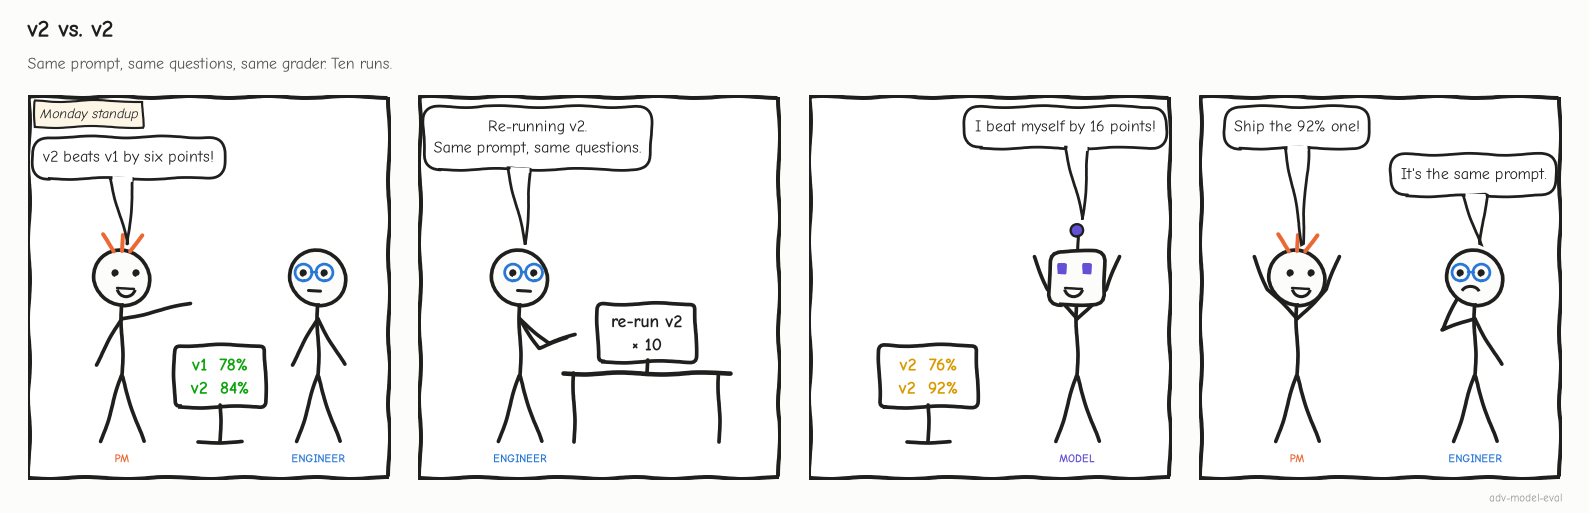

<sub>🖼️ *When the identical prompt swings 16 points between runs, a 6-point gap between two prompts is inside the noise. Shipping the best run is cherry-picking a dice roll.*</sub>


**Bridge:** if one 50-question run can't separate v1 from v2, how big does the test set need to be? You can calculate that *before* you build it.

### Task 6: How Many Test Cases Do You Actually Need?

#### Goal
Write a sample-size calculator, then use the variance you measured in Task 5 to size Brightbook's next eval.

> 📐 **Key idea: power analysis.** Decide the smallest change you would act on, **δ** (say 3 points, written 0.03). Then ask: how many questions *n* do I need so that, if the true change is δ, the test detects it 80% of the time (**power** = 0.80) while false alarms stay at 5% (**α** = 0.05)? For a paired comparison (Miller, 2024):
>
> **n = (z<sub>α/2</sub> + z<sub>β</sub>)² · Var(d) / δ²**
>
> | Symbol | Meaning | Here |
> |---|---|---|
> | z<sub>α/2</sub> | normal-curve cutoff for a two-sided 5% false-alarm rate | 1.96 |
> | z<sub>β</sub> | normal-curve cutoff for 80% power | 0.84 |
> | Var(d) | **variance** (SD², the average squared distance from the mean) of one question's v2 − v1 difference | measured in Task 5 |
> | δ | smallest change worth detecting, as a fraction | 0.03 |
>
> A **z-cutoff** counts SEs from the center of the bell curve that repeated eval results follow: 95% land within ±1.96 SE. Because n grows with 1/δ², **halving the change you want to detect costs 4× the questions.**
>
> Var(d) has two parts. **σ²** is answer randomness *within* a question; averaging K answers per question shrinks it to σ²/K. **ω²** is how much the true gain differs *between* questions; K cannot shrink it. So Var(d) = ω² + (σ²<sub>v1</sub> + σ²<sub>v2</sub>) / K. An unpaired design (two separate question sets) has the much larger variance p₁(1−p₁) + p₂(1−p₂). Read backwards, the formula also gives the smallest change a set of *n* questions can detect, the **minimum detectable effect (MDE)** = (z<sub>α/2</sub> + z<sub>β</sub>) · √(Var(d) / n).

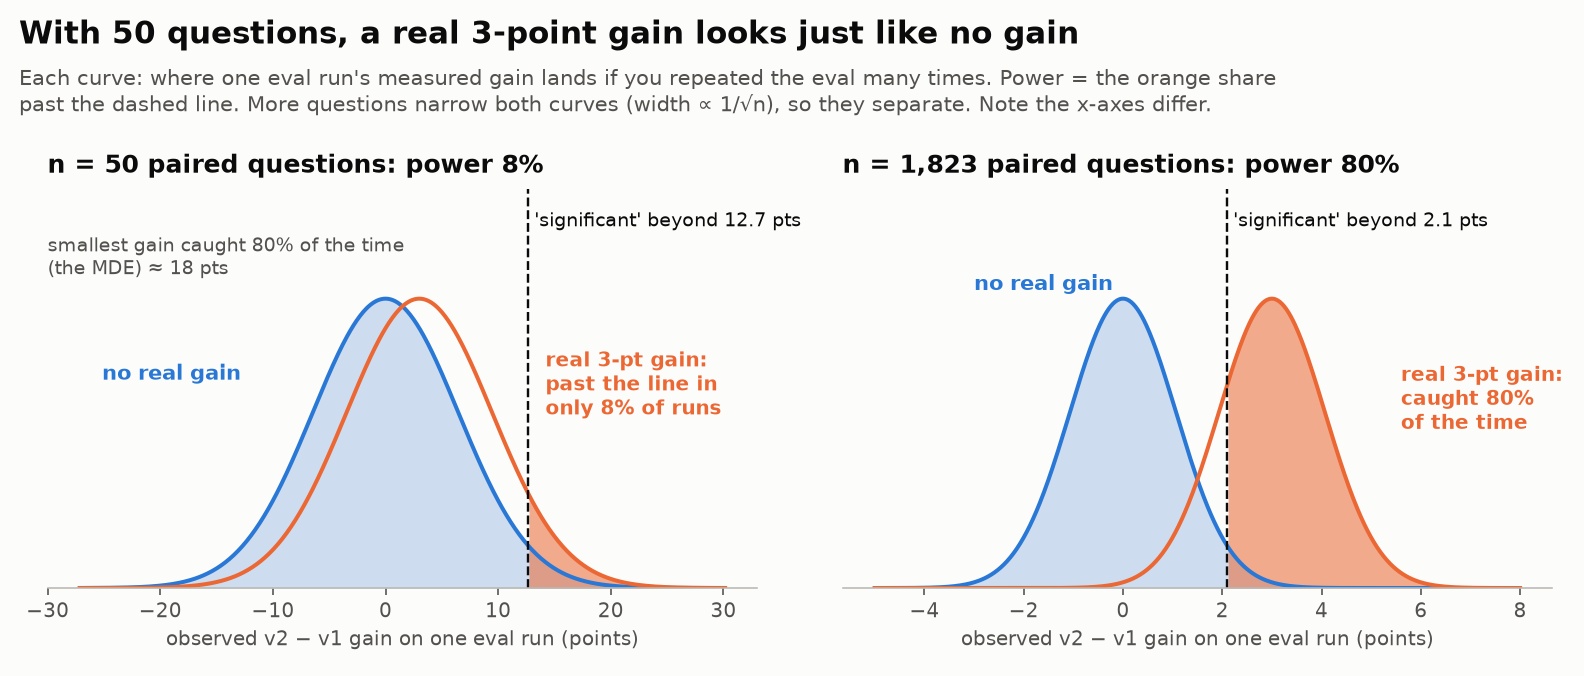

<sub>🖼️ *Power, drawn with this lab's measured variance. Adding questions doesn't move the curves; it narrows them until they separate.*</sub>

#### Steps
1. 🔮 **Predict:** to reliably detect a 3-point improvement with a paired design, how many questions do you need? **100 / 300 / 1,000 / 3,000?**
2. **🧠 Exercise 6A:** translate the formula into `cases_needed`. Run the ✅ check: one test case is Miller's published example (δ = 3 points, Var = 1/9 → **969** questions).
3. Run the planning cell.

<details><summary>💡 Hint 1</summary>

`stats.norm.ppf(0.975)` is 1.96 and `stats.norm.ppf(0.80)` is 0.84.
</details>

<details><summary>✅ Full solution</summary>

```python
def cases_needed(delta, var_per_question, alpha=0.05, power=0.80):
    z_alpha = stats.norm.ppf(1 - alpha / 2)
    z_beta = stats.norm.ppf(power)
    return math.ceil((z_alpha + z_beta) ** 2 * var_per_question / delta ** 2)
```
</details>

In [ ]:
# 🧠 YOUR TURN — Exercise 6A: a sample-size calculator
def cases_needed(delta, var_per_question, alpha=0.05, power=0.80):
    """Smallest number of questions that detects a true change of `delta` (0.03 = 3 points)
    with a two-sided test at level `alpha` and the given `power`."""
    # TODO: translate the 📐 formula into code. You need two z-cutoffs: stats.norm.ppf(q) returns the cutoff
    #       with a share q of the bell curve to its left. A two-sided test splits alpha over both tails.
    #       The answer is a WHOLE number of questions. Sanity check: cases_needed(0.03, 1 / 9) == 969.
    raise NotImplementedError("Exercise 6A")

In [ ]:
# ✅ CHECK 6A
cases_needed = use_or_fallback(
    "6A", cases_needed, _reference_cases_needed,
    cases=[(0.03, 1 / 9), (0.05, 0.2), (0.10, 0.3, 0.05, 0.90)],
)
print(f"Miller (2024) worked example: δ = 3 pts, Var = 1/9 → {cases_needed(0.03, 1 / 9)} questions")

In [ ]:
# Variance pieces, estimated from Task 5's re-runs (10 answers per question per version)
s2_v1 = R1.var(axis=0, ddof=1).mean()             # within-question answer randomness, v1
s2_v2 = R2.var(axis=0, ddof=1).mean()             # ... and v2
omega2 = max(0.0, np.var(R2.mean(axis=0) - R1.mean(axis=0), ddof=1) - (s2_v1 + s2_v2) / K)   # between-question

designs = {
    "Unpaired (separate question sets)": r1 * (1 - r1) + r2 * (1 - r2),
    "Paired, 1 answer per question": omega2 + s2_v1 + s2_v2,
    "Paired, 5 answers per question": omega2 + (s2_v1 + s2_v2) / 5,
}
z_sum = stats.norm.ppf(0.975) + stats.norm.ppf(0.80)
plan = pd.DataFrame([
    {"design": name, "Var(d)": round(v, 3),
     **{f"n for {int(100 * dl)} pts": cases_needed(dl, v) for dl in (0.03, 0.05, 0.10)},
     "smallest change n=50 can detect": f"{100 * z_sum * math.sqrt(v / n):.0f} pts"}
    for name, v in designs.items()
])
display(plan)

n_unp3, n_p3, n_k3 = plan["n for 3 pts"]
mde_p1 = 100 * z_sum * math.sqrt(designs["Paired, 1 answer per question"] / n)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
deltas = np.linspace(0.02, 0.20, 60)
for (name, v), color in zip(designs.items(), [PALETTE[6], PALETTE[0], PALETTE[2]]):
    ns = [cases_needed(dl, v) for dl in deltas]
    ax.plot(100 * deltas, ns, color=color, label=name)
ax.axhline(n, color="#0b0b0b", lw=1, ls="--")
ax.annotate(f"your golden set: {n} questions", (2, n), xytext=(0, -14), textcoords="offset points", fontsize=10)
ax.set_yscale("log")
ax.set_xlabel("smallest true change you want to detect (points)")
ax.set_ylabel("questions needed (log scale)")
ax.set_title(f"Your {n} cases can only detect changes of about {mde_p1:.0f} points or more")
ax.legend(loc="upper right", fontsize=9)
plt.show()

insight(
    f"Detecting a 3-point gain takes {n_p3:,} paired questions: {n_p3 / n:.0f}× your golden set",
    f"Unpaired, it's {n_unp3:,} questions *per version*. Your {n}-case set can only detect changes of about "
    f"{mde_p1:.0f} points, so it could never have confirmed (or ruled out) a 6-point gain. Averaging 5 answers per "
    f"question cuts the requirement to {n_k3:,} questions, because here most of the variance is answer randomness "
    f"(σ² ≈ {s2_v1:.2f} per version) rather than real per-question differences (ω² ≈ {omega2:.3f}). "
    "Rule of thumb: **run the power calculation before you build the golden set, and size it for the smallest change "
    "you would act on.**",
)
insight(
    "About 1,000 questions to see 3 points (Miller, 2024)",
    "Miller's worked example: detecting δ = 3 points at α = 0.05 with 80% power (ω² = 1/9) needs about **969 "
    "questions**, so new evals should have at least about 1,000. Resampling helps small evals: with n = 198, raising K "
    "from 1 to 10 answers per question cut the minimum detectable effect from 13.2% to 7.5%.",
    kind="research",
)

#### Checkpoint
The check line, the Miller example (969), a 3-row planning table, a chart with three falling curves and a dashed line at 50, and two cards.

#### Expected Output
```
✅ Exercise 6A: your function matches the reference on 3 test cases. Using YOUR version.
Miller (2024) worked example: δ = 3 pts, Var = 1/9 → 969 questions
```

| design | Var(d) | n for 3 pts | n for 5 pts | n for 10 pts | smallest change n=50 can detect |
|---|---|---|---|---|---|
| Unpaired (separate question sets) | 0.306 | 2669 | 961 | 241 | 22 pts |
| Paired, 1 answer per question | 0.209 | 1823 | 656 | 164 | 18 pts |
| Paired, 5 answers per question | 0.050 | 437 | 157 | 40 | 9 pts |

💡 card: *"Detecting a 3-point gain takes 1,823 paired questions: 36× your golden set."*

> 🏭 **At work:** 1,800 expert-graded questions is weeks of a tax pro's time, which is why teams grade at scale with an LLM judge. Can you trust the judge?

# Part B: Can you trust the grader?

### Task 7: Calibrate the Judge Against the Tax Pro

#### Goal
Measure how well the LLM judge agrees with the tax pro, using metrics that don't flatter it.

> 📐 **Key idea: judge calibration.** Treat the judge as a classifier and the tax pro's label as ground truth. In this lab **PASS is the positive class** (the "yes" label), and this 2×2 table is the judge's **confusion matrix**:
>
> | | Judge PASS | Judge FAIL |
> |---|---|---|
> | **Expert PASS** | TP (agree) | FN (judge too harsh) |
> | **Expert FAIL** | FP (**judge lets a bad answer through**) | TN (judge catches it) |
>
> - **TPR** = TP / (TP + FN): share of good answers the judge passes.
> - **TNR** = TN / (TN + FP): share of **bad answers the judge catches**. For a tax product, the number that matters most.
> - **Raw agreement** = (TP + TN) / n. Misleading when labels are **imbalanced** (here, most answers pass): a judge that always says PASS agrees with the expert on every good answer.
> - **Cohen's κ** = (agreement − p<sub>e</sub>) / (1 − p<sub>e</sub>), where p<sub>e</sub> is the agreement two raters would reach by chance given only their PASS rates. κ = 0 is chance level, κ = 1 perfect. The realistic ceiling is not 1 but how well two experts agree with each other.
>
> ⚠️ Some teams make **FAIL** the positive class, which swaps the names TPR and TNR. Say which convention you use.

#### Steps
1. 🔮 **Predict:** the judge agrees with the tax pro on 85% of the 200 calibration answers. Good enough for production? And what agreement would a "judge" that **always says PASS** get?
2. **🧠 Exercise 7A:** finish `judge_metrics` (the confusion counts are done for you). Run the ✅ check.
3. Run the analysis cell. It compares the judge with an always-PASS rubber stamp and with a **second tax pro** on 60 double-labeled answers.

<details><summary>💡 Hint 1: chance agreement</summary>

P(expert PASS) = (tp + fn) / n and P(judge PASS) = (tp + fp) / n. Chance agreement is P(both PASS) + P(both FAIL) if they were independent: `p_e = pe_pass * pj_pass + (1 - pe_pass) * (1 - pj_pass)`.
</details>

<details><summary>✅ Full solution</summary>

```python
    agreement = (tp + tn) / n
    tpr = tp / (tp + fn)
    tnr = tn / (tn + fp)
    pe_pass, pj_pass = (tp + fn) / n, (tp + fp) / n
    p_e = pe_pass * pj_pass + (1 - pe_pass) * (1 - pj_pass)
    kappa = (agreement - p_e) / (1 - p_e)
    return {"tp": tp, "fn": fn, "tn": tn, "fp": fp,
            "agreement": agreement, "tpr": tpr, "tnr": tnr, "kappa": kappa}
```
</details>

In [ ]:
# 🧠 YOUR TURN — Exercise 7A: judge vs expert
def judge_metrics(expert, judge):
    """expert, judge: 0/1 labels (1 = PASS) on the same answers.
    Returns {"tp", "fn", "tn", "fp", "agreement", "tpr", "tnr", "kappa"}."""
    e, j = np.asarray(expert).astype(int), np.asarray(judge).astype(int)
    tp = int(((e == 1) & (j == 1)).sum())    # both say PASS
    fn = int(((e == 1) & (j == 0)).sum())    # judge FAILs a good answer (too harsh)
    tn = int(((e == 0) & (j == 0)).sum())    # judge catches a bad answer
    fp = int(((e == 0) & (j == 1)).sum())    # judge PASSes a bad answer  <- the dangerous cell
    n = len(e)
    # TODO: agreement, TPR, TNR and Cohen's κ from the four counts (definitions in the 📐 box); return all 8 keys.
    #       The thinking part is p_e: how often would two raters with THESE PASS rates agree if each labeled
    #       at random? (Hint 1 below if stuck.)
    raise NotImplementedError("Exercise 7A")

In [ ]:
# ✅ CHECK 7A
judge_metrics = use_or_fallback(
    "7A", judge_metrics, _reference_judge_metrics,
    cases=[(calib.expert_pass, calib.judge_pass), ([1, 1, 0, 0, 1, 0], [1, 0, 0, 1, 1, 0]), ([1, 0] * 5, [1, 0] * 5)],
)

In [ ]:
jm = judge_metrics(calib.expert_pass, calib.judge_pass)
rubber = judge_metrics(calib.expert_pass, np.ones(len(calib), dtype=int))     # a "judge" that always says PASS
dbl = calib.dropna(subset=["expert2_pass"])
hh = judge_metrics(dbl.expert_pass, dbl.expert2_pass.astype(int))             # tax pro vs tax pro
jj = judge_metrics(dbl.expert_pass, dbl.judge_pass)                            # judge vs tax pro, same 60 answers
n_fail = jm["tn"] + jm["fp"]
pe_pass, pj_pass = (jm["tp"] + jm["fn"]) / len(calib), (jm["tp"] + jm["fp"]) / len(calib)   # each rater's PASS rate
p_chance = pe_pass * pj_pass + (1 - pe_pass) * (1 - pj_pass)                                  # agreement by luck alone

display(pd.DataFrame({"judge PASS": [jm["tp"], jm["fp"]], "judge FAIL": [jm["fn"], jm["tn"]]},
                     index=["expert PASS", "expert FAIL"]))
tiles([
    ("Raw agreement", pct(jm["agreement"]), f"always-PASS gets {pct(rubber['agreement'], 1)}", "warning"),
    ("Cohen's κ", f"{jm['kappa']:.2f}", f"tax pro vs tax pro: {hh['kappa']:.2f}", "serious"),
    ("TPR (good answers passed)", f"{jm['tpr']:.2f}", f"{jm['tp']} of {jm['tp'] + jm['fn']}", "good"),
    ("TNR (bad answers caught)", f"{jm['tnr']:.2f}", f"{jm['tn']} of {n_fail} failures", "critical"),
])
print(f"On the {len(dbl)} double-labeled answers: tax pro vs tax pro κ = {hh['kappa']:.2f}, "
      f"judge vs tax pro κ = {jj['kappa']:.2f}")

insight(
    f"{pct(jm['agreement'])} agreement sounds great. A rubber stamp that always says PASS scores {pct(rubber['agreement'], 1)}.",
    f"The judge's κ is only {jm['kappa']:.2f}, and it catches just {jm['tn']} of the {n_fail} answers the tax pro "
    f"failed (TNR {jm['tnr']:.2f}). Almost everything passes, so agreement is dominated by easy PASS/PASS cases: two raters who ignored the "
    f"answers and just kept these PASS rates ({pct(pe_pass, 1)} expert, {pct(pj_pass, 1)} judge) would agree "
    f"{pct(p_chance)} of the time by luck, and κ only credits what's above that. On the "
    f"same {len(dbl)} answers, two tax pros agree with κ = {hh['kappa']:.2f}; the judge gets {jj['kappa']:.2f}. "
    "Rule of thumb: **on imbalanced labels report TPR, TNR and κ, never raw agreement, and benchmark the judge "
    "against human-human agreement.**",
    kind="surprise",
)
insight(
    "Binary judges, 100–200 labels, and a human ceiling",
    "Practitioner guidance (Husain & Shankar evals FAQ, Sept 2026): one binary PASS/FAIL judge per failure mode; label "
    "100–200 examples per failure mode, split train / dev / test, with roughly 30–50 PASS **and 30–50 FAIL** examples "
    f"in each of dev and test. (Your calibration set has {n_fail} FAILs in total.) HealthBench (OpenAI, 2025) found "
    "model-physician agreement about equal to physician-physician agreement: the realistic target for a judge is "
    "human-human agreement, not 100%.",
    kind="research",
)

#### Checkpoint
A 2×2 confusion table, four tiles (one red), the double-labeling line, and two cards.

#### Expected Output
```
✅ Exercise 7A: your function matches the reference on 3 test cases. Using YOUR version.
```
| | judge PASS | judge FAIL |
|---|---|---|
| expert PASS | 158 | 7 |
| expert FAIL | 23 | 12 |

Tiles: agreement **85%** (always-PASS gets **82.5%**), κ **0.37** (tax pro vs tax pro **0.79**), TPR **0.96**, TNR **0.34** (12 of 35).
```
On the 60 double-labeled answers: tax pro vs tax pro κ = 0.79, judge vs tax pro κ = 0.49
```
🤯 card: *"85% agreement sounds great. A rubber stamp that always says PASS scores 82.5%."*

![Four-panel comic: the bewigged LLM judge boasts 85% agreement with the tax pro and the PM wants to promote it; the engineer points to a sign that says PASS to everything; a screen shows the sign at 82.5% and the judge at 85%, and the PM panics; the tax expert says the judge passed 23 of her 35 wrong answers, and the judge replies they were beautifully formatted](attachment:comic-rubber-stamp.png)

<sub>🖼️ *When most answers pass, agreement rewards saying PASS. The judge's 85% is 2.5 points better than a signpost; TNR is the number that sees the 23 wrong answers.*</sub>

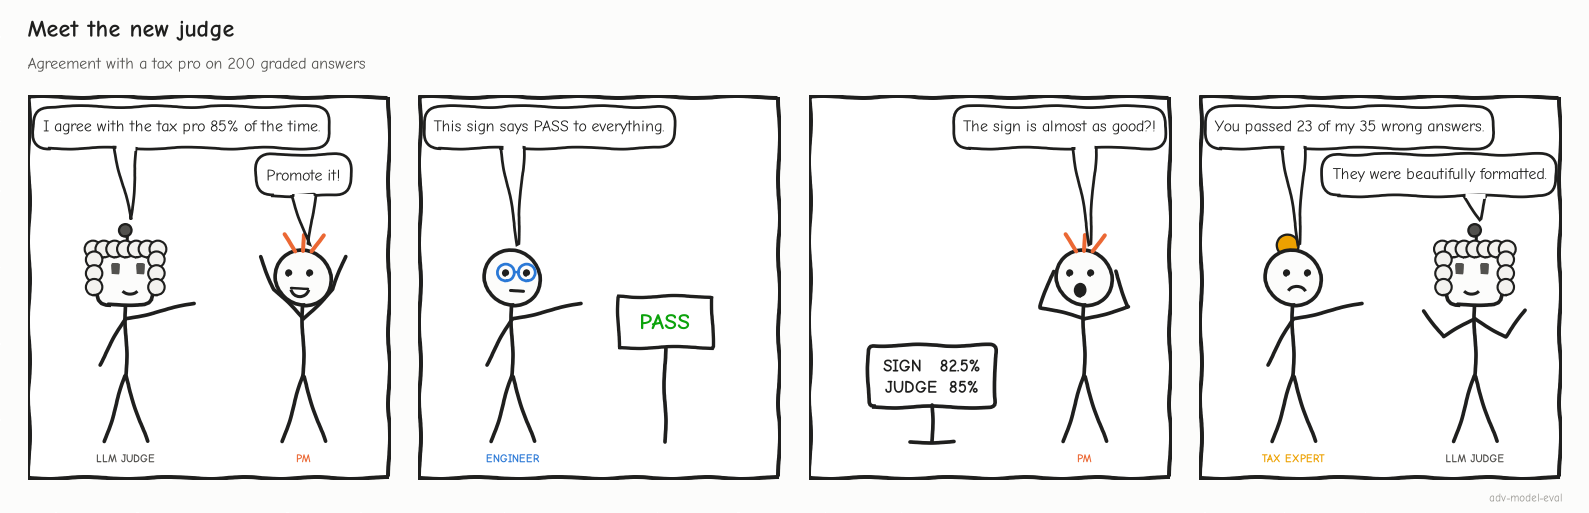

**Bridge:** the judge misses about two-thirds of real failures. So what is v2's production pass rate *really*?

### Task 8: Correct the Judge's Number

#### Goal
Turn the judge-reported 90% into an honest estimate of the true pass rate, with an interval that includes the uncertainty in the judge's own error rates.

> 📐 **Key idea: the Rogan-Gladen correction.** The judge's pass rate is a blend: true passes it caught plus failures it waved through. With θ the true pass rate, p<sub>obs</sub> the judge-reported rate, and TPR and TNR from Task 7:
>
> **p<sub>obs</sub> = θ·TPR + (1 − θ)·(1 − TNR)**
>
> Solve that for θ and you have the **Rogan-Gladen** estimate θ̂: Exercise 8A.
>
> Your answer will divide by **TPR + TNR − 1** (Youden's J; `youden` in the code), the share of any real change that survives the judge. It must be above 0: the judge must beat chance. TPR and TNR are themselves estimates from 200 labels, so the CI comes from a **bootstrap** (Task 4): resample the calibration set and the production set *with replacement* many times, recompute θ̂ each time, and take the middle 95% of the results. The harness's `bootstrap_corrected` does this with *your* correction function. (The `judgy` Python package implements the same correction and bootstrap; check your installed version's argument names.)


#### Steps
1. 🔮 **Predict:** after correcting for the judge's error rates, is v2's production pass rate above or below the 85% GA bar?
2. **🧠 Exercise 8A (derive):** solve the blend for θ on paper, then implement `rogan_gladen`. Run the ✅ check (its test cases include the worked example from the course research notes: p<sub>obs</sub> = 0.70, TPR 0.90, TNR 0.80 → 0.714).
3. Run the analysis cell.
4. 🎛️ Play with the judge slider after the Checkpoint.

<details><summary>🧮 Check your algebra</summary>

p<sub>obs</sub> = θ·TPR + 1 − TNR − θ + θ·TNR = θ·(TPR + TNR − 1) + (1 − TNR), so **θ̂ = (p<sub>obs</sub> + TNR − 1) / (TPR + TNR − 1)**.
</details>

<details><summary>✅ Full solution</summary>

```python
def rogan_gladen(p_obs, tpr, tnr):
    youden = tpr + tnr - 1
    if youden <= 0:
        raise ValueError("Judge is no better than chance (TPR + TNR <= 1); correction is undefined.")
    theta = (p_obs + tnr - 1) / youden
    return min(1.0, max(0.0, theta))
```
</details>

In [ ]:
# 🧠 YOUR TURN — Exercise 8A: correct a judge-reported pass rate
def rogan_gladen(p_obs, tpr, tnr):
    """Estimate the TRUE pass rate from a judge-reported pass rate (1 = PASS is the positive class).
    Returns a value clipped to [0, 1]."""
    # TODO 1: solve the blend  p_obs = θ·TPR + (1 − θ)·(1 − TNR)  for θ (on paper first), then code it.
    # TODO 2: for which judges is your formula undefined or meaningless? Raise ValueError for them.
    # TODO 3: sampling noise can push θ outside [0, 1]. Clip it.
    raise NotImplementedError("Exercise 8A")

In [ ]:
# ✅ CHECK 8A
rogan_gladen = use_or_fallback(
    "8A", rogan_gladen, _reference_rogan_gladen,
    cases=[(0.70, 0.90, 0.80), (0.70, 0.90, 0.70), (0.95, 0.90, 0.50)],
)

In [ ]:
p_obs = prod.judge_pass.mean()
judge_ci = wilson_ci(int(prod.judge_pass.sum()), len(prod))
corrected = rogan_gladen(p_obs, jm["tpr"], jm["tnr"])
boot = bootstrap_corrected(calib.expert_pass, calib.judge_pass, prod.judge_pass, rogan_gladen)
youden = jm["tpr"] + jm["tnr"] - 1

tiles([
    ("Judge-reported pass rate", pct(p_obs, 1), f"±{50 * (judge_ci[1] - judge_ci[0]):.1f} pts (Wilson, n={len(prod):,})", None),
    ("Corrected pass rate", pct(corrected, 1), f"GA bar {pct(LAUNCH_BAR)}", "good" if corrected >= LAUNCH_BAR else "critical"),
    ("Corrected 95% CI", f"{pct(boot['lo'])}–{pct(boot['hi'])}", f"{100 * (boot['hi'] - boot['lo']):.0f} pts wide (bootstrap)", "warning"),
    ("TPR + TNR − 1", f"{youden:.2f}", "share of any real change the judge passes on", "serious"),
])

fig, ax = plt.subplots(figsize=(8.5, 2.6))
rows = [("Judge-reported (Wilson CI)", p_obs, judge_ci, PALETTE[6]),
        ("Corrected (bootstrap CI)", corrected, (boot["lo"], boot["hi"]), PALETTE[2])]
for y, (label, est, (lo, hi), color) in enumerate(rows):
    ax.plot([100 * lo, 100 * hi], [y, y], color=color, lw=3, solid_capstyle="round")
    ax.plot(100 * est, y, "o", color=color, markersize=9, markeredgecolor="#fcfcfb", markeredgewidth=2)
    ax.annotate(f"{100 * est:.1f}%", (100 * est, y), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=10)
ax.axvline(100 * LAUNCH_BAR, color="#0b0b0b", lw=1, ls="--")
ax.annotate(f"GA bar {pct(LAUNCH_BAR)}", (100 * LAUNCH_BAR, 1.45), xytext=(4, 0), textcoords="offset points", fontsize=10)
ax.set_yticks([0, 1], [r[0] for r in rows])
ax.set_ylim(-0.6, 1.7)
ax.set_xlabel("v2 production pass rate (%)")
ax.set_title(f"Judge says {pct(p_obs)}; corrected, it's {pct(corrected)}: below the GA bar")
ax.grid(axis="y", visible=False)
plt.show()

insight(
    f"Corrected for judge error, v2's production pass rate is {pct(corrected, 1)}, not {pct(p_obs, 1)}",
    f"The judge's own interval ({pct(judge_ci[0], 1)}–{pct(judge_ci[1], 1)}) looks precise, but it measures the *judge*, "
    f"not the answers. Propagating the uncertainty in TPR and TNR (only {n_fail} FAIL labels) gives an honest 95% CI of "
    f"{pct(boot['lo'], 1)}–{pct(boot['hi'], 1)}, {100 * (boot['hi'] - boot['lo']):.0f} points wide. The point estimate is "
    f"{100 * (p_obs - corrected):.1f} points below the dashboard and below the {pct(LAUNCH_BAR)} GA bar. Rule of thumb: "
    "**publish the corrected rate with its bootstrap CI, never the raw judge rate.**",
)
insight(
    f"This judge passes on only {youden:.0%} of any real change",
    f"Observed change = true change × (TPR + TNR − 1). A real 5-point regression in v3 would show up on the judge "
    f"dashboard as a {5 * youden:.1f}-point blip, easy to dismiss as noise while customers get wrong tax answers. "
    "The same denominator is why the corrected CI is so wide. Fix the weaker of TPR and TNR first: label more FAIL "
    "examples and tighten the judge's rubric on the failure modes it misses.",
    kind="warning",
)

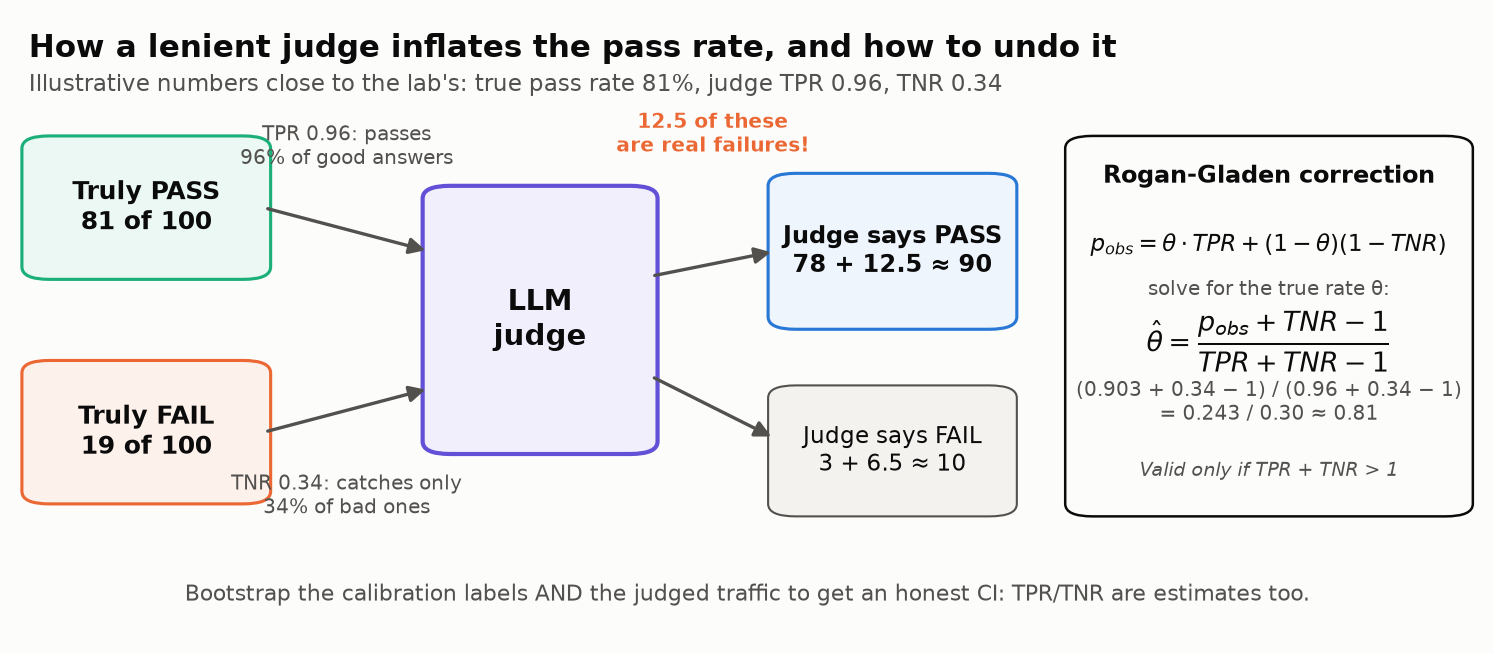

<sub>🖼️ *What you just computed: a lenient judge turns most real failures into PASSes; your formula runs the arithmetic backwards.*</sub>

#### Checkpoint
The check line, four tiles (two red), a two-row interval chart with a dashed bar at 85%, and two cards.

#### Expected Output
```
✅ Exercise 8A: your function matches the reference on 3 test cases. Using YOUR version.
```
Tiles: judge-reported **90.1%** (±1.3 pts), corrected **81.3%**, corrected 95% CI **59%–93%** (34 pts wide), TPR + TNR − 1 = **0.30**.
💡 card: *"Corrected for judge error, v2's production pass rate is 81.3%, not 90.1%"*.
⚠️ card: *"This judge passes on only 30% of any real change"* (a 5-point regression would look like a **1.5**-point blip).

> 🏭 **In production:** if Brightbook's compliance report quoted "90% of AI tax answers are correct" from this judge, it would overstate quality by about 9 points. In regulated domains, publish corrected rates with intervals, and say how the judge was validated.

#### 🎛️ Try it: labels or a better judge?

The corrected interval is 34 points wide. You can buy more expert labels, or fix the judge's rubric. The cell draws three reference designs; the sliders add **your** design in orange. Drag **expert labels** to 3,000, then reset it and drag **TNR** to 0.80: which shrinks the bar faster? (A *parametric* bootstrap: it simulates new label sets from the rates themselves, so it redraws instantly.)

#### Expected Output (default view)
Title: *"Fixing the judge narrows the CI more than 4× the labels (11 vs 16 pts)"*. Rows: today **59–93%** (34 pts), 4× labels **72–88%** (16 pts), TNR 0.80 **76–86%** (11 pts).


In [ ]:
# 🎛️ LABELS OR A BETTER JUDGE? A fast *parametric* bootstrap: simulate new calibration sets and a new judged
# production run from the rates themselves, then recompute the corrected pass rate 4,000 times.
def corrected_ci(tpr, tnr, n_labels, theta=corrected, B=4000):
    rng = np.random.default_rng([505, 77])
    n_pos = round(n_labels * (jm["tp"] + jm["fn"]) / len(calib))      # keeps the lab's 82.5% PASS share
    n_neg = n_labels - n_pos
    p_judge = theta * tpr + (1 - theta) * (1 - tnr)                     # what this judge would report
    tpr_b = rng.binomial(n_pos, tpr, B) / n_pos
    tnr_b = rng.binomial(n_neg, tnr, B) / n_neg
    p_b = rng.binomial(len(prod), p_judge, B) / len(prod)
    J = tpr_b + tnr_b - 1
    th = np.clip((p_b[J > 0] + tnr_b[J > 0] - 1) / J[J > 0], 0, 1)
    return np.percentile(th, [2.5, 97.5])


def ci_ladder(yours=None):
    rows = [("Today: TNR 0.34, 200 labels", jm["tpr"], jm["tnr"], 200, PALETTE[6]),
            ("Label 4× more (800)", jm["tpr"], jm["tnr"], 800, PALETTE[0]),
            ("Fix the rubric: TNR 0.80, 200 labels", jm["tpr"], 0.80, 200, PALETTE[2])]
    if yours:
        rows.append((f"Yours: TPR {yours[0]:.2f}, TNR {yours[1]:.2f}, {yours[2]:,} labels", *yours, PALETTE[1]))
    widths = {}
    fig, ax = plt.subplots(figsize=(8.5, 0.55 * len(rows) + 1.6))
    for y, (label, a, b, n_lab, color) in enumerate(rows[::-1]):
        lo, hi = corrected_ci(a, b, n_lab)
        widths[label] = hi - lo
        ax.plot([100 * lo, 100 * hi], [y, y], color=color, lw=4, solid_capstyle="round")
        ax.plot(100 * corrected, y, "o", color=color, ms=8, mec="#fcfcfb", mew=2)
        ax.annotate(f"{100 * lo:.0f}–{100 * hi:.0f}% ({100 * (hi - lo):.0f} pts)", (100 * hi, y), xytext=(8, -4),
                    textcoords="offset points", fontsize=9.5, color="#52514e")
    ax.axvline(100 * LAUNCH_BAR, color="#0b0b0b", lw=1, ls="--")
    ax.annotate(f"GA bar {pct(LAUNCH_BAR)}", (100 * LAUNCH_BAR, len(rows) - 0.45), xytext=(4, 0),
                textcoords="offset points", fontsize=9.5)
    ax.set_yticks(range(len(rows)), [r[0] for r in rows[::-1]], fontsize=9.5)
    ax.set_ylim(-0.6, len(rows) - 0.2)
    ax.set_xlim(50, 105)
    ax.set_xlabel("corrected v2 production pass rate (%), bar = 95% CI")
    ax.grid(axis="y", visible=False)
    w_fix, w_lab = widths[rows[2][0]], widths[rows[1][0]]
    ax.set_title(f"Fixing the judge narrows the CI more than 4× the labels ({100 * w_fix:.0f} vs {100 * w_lab:.0f} pts)"
                 if yours is None else "Your setting (orange) vs the three reference designs")
    plt.show()


ci_ladder()               # the default view (what Run All shows)

try:
    import ipywidgets as widgets
    _ci_out = widgets.Output()
    _style = {"description_width": "initial"}
    _sl = {"tpr": widgets.FloatSlider(value=round(jm["tpr"], 2), min=0.70, max=0.99, step=0.01, description="TPR", style=_style, continuous_update=False),
           "tnr": widgets.FloatSlider(value=round(jm["tnr"], 2), min=0.30, max=0.95, step=0.01, description="TNR", style=_style, continuous_update=False),
           "n": widgets.IntSlider(value=200, min=100, max=3000, step=100, description="expert labels", style=_style, continuous_update=False)}

    def _redraw(_=None):
        with _ci_out:
            _ci_out.clear_output(wait=True)
            ci_ladder((_sl["tpr"].value, _sl["tnr"].value, _sl["n"].value))

    for _s in _sl.values():
        _s.observe(_redraw, names="value")
    display(widgets.VBox([widgets.HTML("<b>🎛️ Try it:</b> drag <b>expert labels</b> to 3,000, then reset it and drag "
                                       "<b>TNR</b> to 0.80. Which shrinks the orange bar faster?"),
                          widgets.HBox(list(_sl.values())), _ci_out]))
except ImportError:
    print("ipywidgets isn't available here, so only the static view is shown.")


# Part C: Decide

### Task 9: Fake Wins on Demand

#### Goal
Check the PM's 10-metric scorecard for "significant" wins, watch chance manufacture them on demand, and see the same trap return over time.

> 📐 **Key idea: multiple comparisons.** One test at p < 0.05 (Task 3) carries a 5% false-alarm rate. Test 10 metrics and the chance that **at least one** crosses 0.05 by luck (the **family-wise error rate**) is 1 − 0.95¹⁰ ≈ 40% (for independent tests). Two standard fixes:
>
> - **Bonferroni:** compare each p-value to 0.05 / 10. Simple and strict.
> - **Holm:** sort the p-values; multiply the smallest by 10, the next by 9, and so on, never letting an adjusted value go down. Same guarantee as Bonferroni, never less powerful.
>
> **Peeking** is the same trap spread over time: check a running test every day, stop at the first p < 0.05, and every look is another lottery ticket.
>
> Best of all: **pre-register** one primary metric, naming it before you look at any result (Brightbook's policy names expert-graded correctness), and treat the rest as **exploratory**: leads to investigate, not wins to report.

#### Steps
1. 🔮 **Predict:** if v2 were identical to v1 on all 10 metrics, how often would at least one metric look "significant" (p < 0.05)? And if you checked a no-difference test every day for 20 days?
2. Run the dashboard cell: exact McNemar p-values per metric, then the Holm adjustment.
3. 🎰 Run the **slot machine**. Every pull is a brand-new dashboard where v2 changes *nothing*. Pull until the fake-win rate settles.
4. Run the peeking cell.

In [ ]:
def holm(pvals):
    """Holm step-down adjusted p-values: controls the chance of ANY false alarm across all metrics tested."""
    p = np.asarray(pvals, float)
    m, order = len(p), np.argsort(p)
    adj, running = np.empty(m), 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj


dash = dashboard.copy()
dash["p_raw"] = [mcnemar_exact_p(f, b) for f, b in zip(dash.v2_fixed, dash.v2_broke)]
dash["p_holm"] = holm(dash.p_raw)
display(dash.round(3))

star = dash.loc[dash.p_raw.idxmin()]
n_raw = int((dash.p_raw < 0.05).sum())
n_holm = int((dash.p_holm < 0.05).sum())
print(f"{n_raw} metric(s) 'significant' at p < 0.05; {n_holm} after Holm.")


#### Checkpoint
A 10-row table with `p_raw` and `p_holm`.

#### Expected Output
The `asks for missing facts` row shows `v2_fixed` 16, `v2_broke` 5, `p_raw` **0.027**, `p_holm` **0.266**. `correct (expert)` shows 5 / 2 and `p_raw` **0.453**.
```
1 metric(s) 'significant' at p < 0.05; 0 after Holm.
```
Is "asks for missing facts" a real win? Build dashboards where you *know* nothing changed, and count.


In [ ]:
# 🎰 THE P-HACKING SLOT MACHINE. Each pull builds a brand-new 10-metric dashboard where v2 is
# IDENTICAL to v1 on every metric (an "A/A test"), then checks each metric at p < 0.05.
SLOT_SEED = 913


def pull_lever(i, n_q=50):
    """Dashboard #i: v1 and v2 answer 50 golden questions with the SAME true quality on all 10 metrics."""
    rng = np.random.default_rng([505, SLOT_SEED, i])
    base = rng.uniform(0.6, 0.92, (len(_METRICS), 1))                                   # each metric's typical pass rate
    q = _sig(np.log(base / (1 - base)) + rng.normal(0, 1.0, (len(_METRICS), n_q)))      # per-question difficulty
    a1, a2 = rng.random(q.shape) < q, rng.random(q.shape) < q                          # same q for both: no real effect
    p = np.array([mcnemar_exact_p(int(f), int(b)) for f, b in zip((~a1 & a2).sum(1), (a1 & ~a2).sum(1))])
    return p, holm(p)


_pulls = []


def slot_machine(n_pulls, show_last=20):
    while len(_pulls) < n_pulls:
        _pulls.append(pull_lever(len(_pulls) + 1))
    raw_wins = sum(bool((p < 0.05).any()) for p, _ in _pulls[:n_pulls])
    holm_wins = sum(bool((h < 0.05).any()) for _, h in _pulls[:n_pulls])
    first = max(0, n_pulls - show_last)
    fig, ax = plt.subplots(figsize=(8.5, 0.27 * (n_pulls - first) + 2.3))
    for r, (p, h) in enumerate(_pulls[first:n_pulls]):
        y = n_pulls - first - 1 - r
        for c, pv in enumerate(p):
            hit = pv < 0.05
            ax.add_patch(plt.Rectangle((c, y + 0.08), 0.92, 0.84, color=PALETTE[1] if hit else "#ecebe7", lw=0))
            if hit:
                ax.text(c + 0.46, y + 0.5, f"p={pv:.3f}", ha="center", va="center", fontsize=6.8, color="#fcfcfb",
                        fontweight="bold")
        if (p < 0.05).any():
            ax.text(10.15, y + 0.5, "FAKE WIN" + (" (survives Holm!)" if (h < 0.05).any() else ""), va="center",
                    fontsize=9, color=PALETTE[1], fontweight="bold")
    ax.set_xlim(0, 12.6)
    ax.set_ylim(0, n_pulls - first)
    ax.set_yticks([n_pulls - first - 1 - r + 0.5 for r in range(n_pulls - first)],
                  [f"pull {first + r + 1}" for r in range(n_pulls - first)], fontsize=8)
    ax.set_xticks([c + 0.46 for c in range(len(_METRICS))], _METRICS, rotation=35, ha="right", fontsize=8.5)
    ax.tick_params(length=0)
    ax.grid(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_visible(False)
    ax.set_title(f"{raw_wins} of {n_pulls} do-nothing dashboards 'found' a winning metric")
    plt.show()
    tiles([
        ("Pulls (A/A dashboards)", n_pulls, "v2 == v1 on all 10 metrics", None),
        ("Fake wins at p < 0.05", f"{raw_wins} ({raw_wins / n_pulls:.0%})", "at least one 'significant' metric", "critical"),
        ("Fake wins after Holm", f"{holm_wins} ({holm_wins / n_pulls:.0%})", "Holm keeps it near 5% or below", "good"),
    ])
    return raw_wins, holm_wins


slot_machine(20)          # the first 20 pulls: what Run All shows

try:                      # 🎛️ live version: works in Colab and Jupyter (ipywidgets 7 or 8)
    import ipywidgets as widgets
    _slot_out = widgets.Output()
    _n = {"pulls": 20}

    def _pull(k):
        def _cb(_):
            _n["pulls"] += k
            with _slot_out:
                _slot_out.clear_output(wait=True)
                slot_machine(_n["pulls"])
        return _cb

    _b1, _b20 = widgets.Button(description="🎰 Pull the lever"), widgets.Button(description="Pull 20 more")
    _b1.on_click(_pull(1))
    _b20.on_click(_pull(20))
    display(widgets.VBox([widgets.HTML("<b>🎛️ Try it:</b> pull until the fake-win rate settles. "
                                       "Watch which metric 'wins' change from pull to pull."),
                          widgets.HBox([_b1, _b20]), _slot_out]))
except ImportError:
    print("ipywidgets isn't available here, so only the static first 20 pulls are shown.")

null_dash = simulate_null_dashboards()
insight(
    f"'{star.metric}' looks like a win (p = {star.p_raw:.3f}), but {pct(null_dash['raw_any'])} of do-nothing "
    "dashboards show one too",
    f"In 4,000 simulated 10-metric dashboards where v2 changes nothing, {pct(null_dash['raw_any'])} had at least one "
    f"metric with p < 0.05. (The exact McNemar test is conservative on 50 cases, meaning its real false-alarm rate is "
    f"below the nominal 5%; with ordinary 5%-level tests it would be "
    f"1 − 0.95¹⁰ = {1 - 0.95**10:.0%}.) Holm brings that down to {pct(null_dash['holm_any'], 1)}, and after Holm "
    f"'{star.metric}' has p = {star.p_holm:.2f}. In this simulation we know the truth: none of the 9 secondary metrics "
    "has a real effect. Rule of thumb: **name ONE primary metric before you look; correct the rest (Holm) or call them "
    "exploratory.**",
    kind="surprise",
)


#### Expected Output (first 20 pulls)
Chart title: *"5 of 20 do-nothing dashboards 'found' a winning metric"*. Tiles: **20** pulls, **5 (25%)** fake wins, **0 (0%)** after Holm. Every "win" is a different metric: chance doesn't care which.
🤯 card: *"'asks for missing facts' looks like a win (p = 0.027), but 24% of do-nothing dashboards show one too"* (5%-level tests: 40%; Holm: 2.3%). Keep pulling: the raw tally hovers around 20–25% (300 pulls: 65, or 22%) while Holm's stays near 1–3% (300 pulls: 4).

Ten metrics are ten tickets in one draw. Brightbook's next temptation buys its tickets one day at a time.


In [ ]:
# 👀 PEEKING: a live A/A test in filing season. v2b only fixes a typo in v2's prompt (identical quality).
# Each day the tax pro grades 60 new production questions answered by both versions. The team checks
# the cumulative McNemar p-value and stops the moment it drops below 0.05.
DAYS, PER_DAY, N_EXP = 20, 60, 2000
rng = np.random.default_rng([505, 31])
d_peek, _ = _latent(rng, N_EXP * DAYS * PER_DAY // 5)                     # 5 questions per conversation
p_q = _sig(_A - d_peek).reshape(N_EXP, DAYS, PER_DAY)                     # same pass probability for both
o1, o2 = rng.random(p_q.shape) < p_q, rng.random(p_q.shape) < p_q
fx, br = (~o1 & o2).sum(2).cumsum(1), (o1 & ~o2).sum(2).cumsum(1)          # cumulative fixed / broke by day
p_day = np.minimum(1.0, 2 * stats.binom.cdf(np.minimum(fx, br), np.maximum(fx + br, 1), 0.5))

looks = [1, 2, 5, 10, 20]
peek, peek_bonf = {}, {}
for k in looks:
    days_checked = np.round(np.linspace(DAYS / k, DAYS, k)).astype(int) - 1    # k evenly spaced looks, last on day 20
    peek[k] = float((p_day[:, days_checked] < 0.05).any(1).mean())
    peek_bonf[k] = float((p_day[:, days_checked] < 0.05 / k).any(1).mean())

fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.plot(looks, [100 * peek[k] for k in looks], "o-", color=PALETTE[1], label="stop at the first p < 0.05")
ax.plot(looks, [100 * peek_bonf[k] for k in looks], "o-", color=PALETTE[2], label="stricter bar per look (p < 0.05 / looks)")
ax.axhline(5, color="#0b0b0b", lw=1, ls="--")
ax.annotate("the 5% you think you're paying", (20, 5), xytext=(-4, 5), textcoords="offset points", ha="right", fontsize=9.5)
for k, dx in ((1, -15), (20, 0)):
    ax.annotate(pct(peek[k]), (k, 100 * peek[k]), xytext=(dx, 8), textcoords="offset points", ha="center", fontsize=10,
                color=PALETTE[1], fontweight="bold")
ax.set_xticks(looks)
ax.set_xlim(-1, 21)
ax.set_ylim(0, 26)
ax.set_xlabel(f"how many times you check the running test over {DAYS} days")
ax.set_ylabel("A/A tests declared 'different' (%)")
ax.set_title(f"Checking daily turns a {pct(peek[1])} false-alarm rate into {pct(peek[20])}")
ax.legend(loc="upper left", fontsize=9)
plt.show()

insight(
    f"Peek every day and {pct(peek[20])} of no-difference tests 'find' a difference; look once and it's {pct(peek[1])}",
    f"Each look is another lottery ticket, and stopping at the first win keeps the winner: this is multiple comparisons "
    f"spread over time. A stricter bar per look (p < 0.05 / {DAYS}) holds it to {pct(peek_bonf[20], 1)}, at the cost of "
    "detecting real changes later. Rule of thumb: **fix the sample size in advance (Task 6) and look once, or use a "
    "sequential test built for repeated looks; never stop an eval the moment it turns green.**",
    kind="warning",
)


#### Expected Output
Chart title: *"Checking daily turns a 4% false-alarm rate into 20%"* (orange line rising; the green "stricter bar per look" line stays under 5%).
⚠️ card: *"Peek every day and 20% of no-difference tests 'find' a difference; look once and it's 4%"*.


**Bridge:** you now have every piece of evidence. Time to decide, and to write it up so others can check your work.

### Task 10: The Decision and Your Eval Report Card

#### Goal
Apply Brightbook's launch policy to the evidence, render the decision, and produce a **report card** you can reuse for any eval at work.

The policy, written as code:

| Outcome | Rule |
|---|---|
| 🚀 **SHIP** | Corrected pass rate's 95% CI lower bound ≥ GA bar, **and** v2 is not worse than v1 (a **non-inferiority** check: gain CI lower bound > −5 pts) |
| ⚠️ **SHIP WITH CAUTION** | Corrected point estimate ≥ GA bar but its CI dips below it, and v2 is not worse |
| 🛑 **BLOCK** | Anything else |

#### Steps
1. 🔮 **Predict:** which verdict will the policy return? Compare with your Task 1 call.
2. Run the decision cell. Read the printed report card: it is built to paste into a PR, a launch doc or Slack.
3. Run the truth-reveal cell (possible only because this is a simulation).

In [ ]:
NONINF_MARGIN = -0.05          # "not worse" = gain CI lower bound above -5 points
improvement_proven = paired_cl["lo"] > 0
not_worse = paired_cl["lo"] > NONINF_MARGIN

if boot["lo"] >= LAUNCH_BAR and not_worse:
    decision = "SHIP"
elif corrected >= LAUNCH_BAR and not_worse:
    decision = "SHIP WITH CAUTION"
else:
    decision = "BLOCK"


def eval_report_card(title, fields):
    """Reusable at work: print an aligned, copy-pasteable eval summary."""
    width = max(len(k) for k in fields)
    print(title)
    print("─" * len(title))
    for k, v in fields.items():
        print(f"{k:<{width}}  {v}")


eval_report_card(f"EVAL REPORT CARD · Brightbook tax-help assistant · v2 vs v1", {
    "Primary metric": "expert-graded correctness (PASS/FAIL by an enrolled agent), pre-registered",
    "Data": f"{n} golden questions in {conv.nunique()} conversations; {len(calib)} expert labels; "
            f"{len(prod):,} judged production answers",
    "v1 / v2 (golden)": f"{pct(r1)} (95% CI {pct(ci1[0])}–{pct(ci1[1])}) / {pct(r2)} (95% CI {pct(ci2[0])}–{pct(ci2[1])})",
    "Paired gain": f"{100 * paired_cl['diff']:+.1f} pts, 95% CI {100 * paired_cl['lo']:+.1f} to "
                   f"{100 * paired_cl['hi']:+.1f} (clustered by conversation); {fixed} fixed / {broke} broke, "
                   f"McNemar p = {p_mcnemar:.2f}",
    "Re-run stability": f"v2 ranged {pct(runs.v2.min())}–{pct(runs.v2.max())} over {K} re-runs of the same questions",
    "Detectable change": f"~{mde_p1:.0f} pts at n = {n}; 3 pts needs {n_p3:,} paired questions ({n_k3:,} with 5 answers each)",
    "Judge vs expert": f"TPR {jm['tpr']:.2f}, TNR {jm['tnr']:.2f}, κ {jm['kappa']:.2f} on {len(calib)} labels "
                       f"({n_fail} FAIL); tax pro vs tax pro κ {hh['kappa']:.2f}",
    "Production pass rate": f"judge {pct(p_obs, 1)} → corrected {pct(corrected, 1)} "
                            f"(bootstrap 95% CI {pct(boot['lo'])}–{pct(boot['hi'])}); GA bar {pct(LAUNCH_BAR)}",
    "Secondary metrics": f"{len(dash) - 1} tested; {n_raw} with raw p < 0.05; {n_holm} after Holm",
    "Decision": decision,
})

tiles([
    ("Paired gain (clustered)", f"{100 * paired_cl['diff']:+.0f} pts",
     f"95% CI {100 * paired_cl['lo']:+.0f} to {100 * paired_cl['hi']:+.0f}", "good" if improvement_proven else "warning"),
    ("Corrected pass rate", pct(corrected), f"CI {pct(boot['lo'])}–{pct(boot['hi'])} vs bar {pct(LAUNCH_BAR)}",
     "good" if boot["lo"] >= LAUNCH_BAR else "warning" if corrected >= LAUNCH_BAR else "critical"),
    ("Judge TNR", f"{jm['tnr']:.2f}", "share of failures caught", "critical" if jm["tnr"] < 0.7 else "good"),
    ("Secondary 'wins'", f"{n_holm} of {len(dash) - 1}", f"after Holm ({n_raw} raw)", "good"),
])

reasons = []
if not improvement_proven:
    reasons.append(f"**Improvement not proven:** {100 * paired_cl['diff']:+.0f} pts, 95% CI {100 * paired_cl['lo']:+.1f} "
                   f"to {100 * paired_cl['hi']:+.1f}. v2 could be up to {-100 * paired_cl['lo']:.0f} points *worse* than v1.")
if corrected < LAUNCH_BAR:
    reasons.append(f"**Below the GA bar:** corrected production pass rate {pct(corrected, 1)} (95% CI "
                   f"{pct(boot['lo'])}–{pct(boot['hi'])}) vs {pct(LAUNCH_BAR)} required. The judge's {pct(p_obs, 1)} is "
                   f"inflated: it catches only {jm['tnr']:.0%} of failures.")
if n_raw > n_holm:
    reasons.append(f"**'{star.metric}' is a multiple-comparisons false alarm** (raw p = {star.p_raw:.3f}, "
                   f"Holm p = {star.p_holm:.2f}).")
reasons.append(f"**Next:** grow the golden set to ~{n_k3:,} paired questions with 5 graded answers each, label 50+ more "
               "FAIL examples and fix the judge's misses, then re-run this report card.")
verdict(decision, reasons)

In [ ]:
# 🔎 TRUTH REVEAL: only a simulation can do this. In real life you never see the last column.
truth_gain = _TRUTH["v2_prod"] - _TRUTH["v1_prod"]
truth_v2 = _TRUTH["v2_prod"]
gain_hit = paired_cl["lo"] <= truth_gain <= paired_cl["hi"]
rate_hit = boot["lo"] <= truth_v2 <= boot["hi"]

reveal = pd.DataFrame([
    {"quantity": "v2 − v1 gain", "PM's number": f"+{100 * gain:.1f} pts",
     "your estimate (95% CI)": f"{100 * paired_cl['diff']:+.1f} pts ({100 * paired_cl['lo']:+.1f} to {100 * paired_cl['hi']:+.1f})",
     "truth": f"{100 * truth_gain:+.1f} pts"},
    {"quantity": "v2 production pass rate", "PM's number": pct(p_obs, 1),
     "your estimate (95% CI)": f"{pct(corrected, 1)} ({pct(boot['lo'], 1)} to {pct(boot['hi'], 1)})",
     "truth": pct(truth_v2, 1)},
    {"quantity": "judge TNR (failures caught)", "PM's number": "not measured",
     "your estimate (95% CI)": f"{jm['tnr']:.2f}", "truth": f"{_TRUTH['judge_tnr']:.2f}"},
]).set_index("quantity")
display(reveal)

insight(
    f"The truth: v2 really is {100 * truth_gain:+.1f} points better, about {truth_gain / gain:.0%} of the claimed gain, "
    f"and it's {pct(truth_v2, 1)} correct: below the bar",
    f"Your gain interval {'contained' if gain_hit else 'missed'} the truth, and your corrected-rate interval "
    f"{'did too' if rate_hit else 'missed it'}. The PM's point estimates were off by {100 * (gain - truth_gain):.1f} and "
    f"{100 * (p_obs - truth_v2):.1f} points. Blocking was right even though v2 is slightly better: *'better than v1'* "
    "and *'good enough for every customer'* are different questions, and only the second one has a bar. "
    "Rule of thumb: **decide on intervals and pre-written rules, not on point estimates.**",
    kind="surprise",
)

#### Checkpoint
An aligned report card, four tiles, a 🛑 **BLOCK** banner with four reasons, and a 3-row truth table.

#### Expected Output
```
EVAL REPORT CARD · Brightbook tax-help assistant · v2 vs v1
...
Paired gain           +6.0 pts, 95% CI -7.1 to +19.1 (clustered by conversation); 5 fixed / 2 broke, McNemar p = 0.45
...
Production pass rate  judge 90.1% → corrected 81.3% (bootstrap 95% CI 59%–93%); GA bar 85%
Secondary metrics     9 tested; 1 with raw p < 0.05; 0 after Holm
Decision              BLOCK
```
Truth table: gain truth **+2.0 pts**; v2 production truth **81.3%**; judge TNR truth **0.36**.
🤯 card: *"The truth: v2 really is +2.0 points better, about 34% of the claimed gain, and it's 81.3% correct: below the bar"*.

#### ✍️ Revisit your Task 1 call

**My Task 1 call was:** `____`  **The evidence says:** `____`

**The one number I'd put in front of the VP:**

**What I would tell the PM (one kind, specific sentence):**

> e.g. "v2 might be a bit better, but 50 cases can't show it, and the judge's 90% is really about 81%. Here's the plan to get a real answer in two weeks."

---

## 🔌 Optional: What a Real Judge Call Looks Like

Everything above used simulated judge verdicts. This section shows how a production judge produces them: a **binary PASS/FAIL verdict for one failure mode**, returned as **structured output** so it can't come back malformed. It runs offline by default (`PROVIDER = "mock"`); the mock judge is deliberately lenient, like the one you calibrated.

| `PROVIDER` | What grades the answers | Needs |
|---|---|---|
| `"mock"` *(default)* | A lenient keyword heuristic, offline | nothing |
| `"openai"` | `OPENAI_MODEL` via the Responses API (`client.responses.parse`) | `OPENAI_API_KEY` in Colab 🔑 Secrets or env, `pip install openai` |
| `"anthropic"` | `ANTHROPIC_MODEL` via `client.messages.parse` | `ANTHROPIC_API_KEY`, `pip install anthropic` |

No `temperature` is sent: current Anthropic models reject sampling parameters, and temperature 0 wouldn't make the judge deterministic anyway (Task 5). To validate a real judge, run it over your expert-labeled calibration answers and pass `(expert, judge)` into `judge_metrics`, as in Task 7.

In [ ]:
# ⚙️ CONFIG — choose what grades the answers (model IDs live only in this cell)
PROVIDER = "mock"                      # "mock" | "openai" | "anthropic"
OPENAI_MODEL = "gpt-6-luna"
ANTHROPIC_MODEL = "claude-haiku-5-5"

import os
from typing import Literal

from pydantic import BaseModel, Field


class JudgeVerdict(BaseModel):
    critique: str = Field(description="One or two sentences comparing the answer with the reference, BEFORE the verdict")
    verdict: Literal["PASS", "FAIL"]


JUDGE_INSTRUCTIONS = (
    "You grade answers from a small-business tax assistant for ONE failure mode: a factually wrong tax rule, "
    "threshold, or deadline. Compare the answer with the reference answer written by a tax professional. "
    "FAIL if the answer states any rule, number or deadline that contradicts the reference; otherwise PASS. "
    "Ignore tone, length and formatting."
)


def _get_secret(name):
    try:
        from google.colab import userdata  # type: ignore
        return userdata.get(name)
    except Exception:
        return os.environ.get(name)


def judge_answer(question, answer, reference):
    prompt = f"QUESTION:\n{question}\n\nREFERENCE ANSWER:\n{reference}\n\nANSWER TO GRADE:\n{answer}"
    if PROVIDER == "openai":
        from openai import OpenAI
        client = OpenAI(api_key=_get_secret("OPENAI_API_KEY"))
        resp = client.responses.parse(model=OPENAI_MODEL, instructions=JUDGE_INSTRUCTIONS, input=prompt,
                                      text_format=JudgeVerdict)
        return resp.output_parsed
    if PROVIDER == "anthropic":
        import anthropic
        client = anthropic.Anthropic(api_key=_get_secret("ANTHROPIC_API_KEY"))
        resp = client.messages.parse(model=ANTHROPIC_MODEL, max_tokens=1024, system=JUDGE_INSTRUCTIONS,
                                     messages=[{"role": "user", "content": prompt}], output_format=JudgeVerdict)
        if resp.stop_reason == "refusal":
            return JudgeVerdict(critique="Model refused to grade.", verdict="FAIL")
        return resp.parsed_output
    # mock: lenient on purpose. It only fails answers that hedge, like many un-calibrated judges.
    hedged = any(w in answer.lower() for w in ("not sure", "i don't know", "can't say"))
    return JudgeVerdict(critique="Mock judge: checks for hedging only.", verdict="FAIL" if hedged else "PASS")


if PROVIDER != "mock" and not _get_secret(f"{PROVIDER.upper()}_API_KEY"):
    print(f"⚠️  No {PROVIDER.upper()}_API_KEY found. Falling back to PROVIDER = 'mock'.")
    PROVIDER = "mock"

QUESTION = "What is the safe-harbor rule for quarterly estimated taxes?"
REFERENCE = ("You generally avoid an underpayment penalty if your estimates total at least 90% of this year's tax or "
             "100% of last year's tax (110% if last year's AGI was over $150,000).")
ANSWERS = {
    "correct": "Pay at least 90% of this year's tax or 100% of last year's (110% if your AGI was over $150k) to avoid the penalty.",
    "confidently wrong": "You're safe as long as you pay 50% of last year's tax across the four quarters.",
    "hedged": "I'm not sure; it depends on your situation, so check with a tax professional.",
}
for label, ans in ANSWERS.items():
    v = judge_answer(QUESTION, ans, REFERENCE)
    print(f"{label:<18} → {v.verdict}   ({v.critique})")
print(f"\nGraded by: {PROVIDER}" + ("" if PROVIDER == "mock" else f" ({OPENAI_MODEL if PROVIDER == 'openai' else ANTHROPIC_MODEL})"))

#### Expected Output (mock)
```
correct            → PASS   (Mock judge: checks for hedging only.)
confidently wrong  → PASS   (Mock judge: checks for hedging only.)
hedged             → FAIL   (Mock judge: checks for hedging only.)

Graded by: mock
```
The mock judge **passes the confidently wrong answer** (50% is not the safe-harbor rule) and fails the honest hedge: exactly the low-TNR behavior you measured in Task 7. A real model judge with a reference answer should FAIL the wrong answer; calibration against expert labels is how you find out whether it does.

---

## Validation or Success Criteria

You've completed the lab if you can explain or demonstrate each of these:

- [ ] Why a 50-case pass rate needs a confidence interval (about ±11 points), and why Wilson beats p ± 1.96·SE for small n.
- [ ] Why a **paired** comparison is tighter than comparing two pass rates, and what the fixed/broke counts tell you.
- [ ] How clustered questions shrink your **effective n**, and how to compute a clustered SE.
- [ ] Why the same prompt on the same questions gives different scores, and why you resample K answers per question rather than trust temperature 0.
- [ ] How many test cases you need to detect a δ-point change at 80% power, and what each symbol in the formula means.
- [ ] Why raw judge agreement misleads on imbalanced data, and what TPR, TNR and κ show instead.
- [ ] How to correct a judge-reported pass rate (Rogan-Gladen) and get a bootstrap CI.
- [ ] Why 10 metrics, or daily peeks at a running test, produce false alarms, and how Holm or a fixed sample size fixes it.
- [ ] How to turn all of it into a policy-based SHIP / BLOCK decision and a report card.

Run the self-test. It should print `✅ All checks passed`.

In [ ]:
# SELF-TEST: the lab's key invariants
assert (k1, k2, n) == (39, 42, 50)
assert (fixed, broke) == (5, 2) and abs(p_mcnemar - 0.453125) < 1e-9
assert paired["lo"] < 0 < paired["hi"], "the paired CI should include zero"
assert ratio_v2 > 1.5 and n_eff < 20, "clustering should inflate the SE"
assert cases_needed(0.03, 1 / 9) == 969
assert jm["agreement"] > 0.8 and jm["kappa"] < 0.5 and jm["tnr"] < 0.5
assert corrected < LAUNCH_BAR <= p_obs, "the judge clears the bar; the corrected rate does not"
assert n_raw >= 1 and n_holm == 0
assert peek[20] > 3 * peek[1], "peeking should inflate false alarms"
assert decision == "BLOCK"
print("✅ All checks passed")

## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `NameError: name 'golden' is not defined` (or `insight`, `pct`, ...) | The lab kit or harness cell wasn't run | Run the three setup cells first, or use *Runtime → Run all* |
| `NameError` for a variable from an earlier task (e.g. `paired_cl`, `R1`, `jm`) | Tasks build on each other | Re-run the earlier task's cells, or *Run all* |
| `❌ Exercise 3A: AssertionError ...` | Your function returns a different number than the reference | Compare with the hints. Common slips: `ddof=0` instead of `ddof=1`; computing `v1 - v2` instead of `v2 - v1` |
| `❌ Exercise 7A: ... missing key 'fn'` (or another key) | Your dict is missing a key | Return all 8 keys: `tp, fn, tn, fp, agreement, tpr, tnr, kappa` |
| `❌ Exercise 8A` on test case 3 | No clipping | Clip θ to [0, 1]: `min(1.0, max(0.0, theta))` |
| Numbers differ slightly from Expected Output | Different `numpy` version changing random streams, or you edited a seed | Directions and conclusions hold; exact decimals may differ in the last digit |
| `AttributeError: 'DataFrame' object has no attribute 'map'` | pandas older than 2.1 | Use `applymap` instead of `map` in Task 5, or upgrade pandas |
| 🎛️ Buttons or sliders show as text, or do nothing | No widget support (plain Jupyter without `ipywidgets`) or the kernel restarted | The static chart drawn above each control is the default result. In Jupyter: `pip install ipywidgets`, then re-run the cell |
| Real-judge section errors | Missing SDK or key | `pip install openai` / `pip install anthropic`, add the key to Colab 🔑 Secrets, or set `PROVIDER = "mock"` |

## Stretch Goal or Extension

**A. Labels or a better judge? (15 min).** The corrected CI is wide because TNR rests on 35 FAIL labels and TPR + TNR − 1 is only 0.30. Pretend the tax pro labels more answers: the simulator's hidden expert verdicts are `_prod_true` (judge verdicts: `_prod_judge`). Build calibration sets of 600, 1,000 and all 2,000 answers (e.g. `idx = np.arange(0, 2000, 2000 // size)`), rerun `bootstrap_corrected(_prod_true[idx], _prod_judge[idx], prod.judge_pass, rogan_gladen)`, and plot CI width against label count. Can labels alone get the CI under 10 points wide? What does that say about fixing the judge first? (Challenge 3 answers the same question in closed form.)

**B. Cluster bootstrap (10 min).** Replace the clustered SE in Task 4 with a bootstrap that resamples whole conversations (10 draws with replacement, 5,000 times). Do you get a similar interval for the paired gain?

**C. Non-inferiority framing (10 min).** Suppose v2 is cheaper and the team only needs it to be *no worse* than v1 by more than 2 points. Using the planner, how many paired questions with K = 5 do you need to show that?

**D. A real judge on your own data (30 min).** Set `PROVIDER` to `"openai"` or `"anthropic"`, write 20 question / reference / answer triples from your own domain, label them yourself, and compute `judge_metrics`. Then compare with a colleague's labels on the same 20: is the judge at human-human agreement?

**E. Read further.** Prediction-powered inference (PPI) is a more general way to combine a few expert labels with many judge labels; look at it once Rogan-Gladen feels natural.

### 🏆 Challenge exercises

Three problems that need thinking more than typing, in rising difficulty. Each starter cell runs as shipped and prints 📝 until you attempt it, then ✅ or ❌. Worked solutions are in the instructor solution file.

#### 🌶️ Challenge 1: Zero failures is not zero risk (derive)

Brightbook's compliance reviewer wants a certificate: *"the assistant echoes a customer's SSN or EIN back in under 1% of answers."* A privacy red-team set found **0 echoes in 50 attempts**.

1. After 0 failures in *n* tests, the one-sided 95% upper bound *u* on the failure rate solves **(1 − u)ⁿ = 0.05**: it is the largest failure rate that would still produce a clean run 5% of the time. Compute it for n = 50.
2. How many consecutive clean answers do you need before *u* ≤ 1%?
3. Compare both with the **rule of three**: after 0 failures in *n*, u ≈ 3/n.

<details><summary>💡 Hint</summary>

Take logs: n · ln(1 − u) = ln(0.05). For part 2, solve for n and round up with `math.ceil`.
</details>


In [ ]:
# 🌶️ CHALLENGE 1: zero failures is not zero risk
def upper_bound_zero_failures(n, conf=0.95):
    """One-sided upper bound on the failure rate after n tests with 0 failures.
    Solve (1 - u) ** n = 1 - conf for u."""
    # TODO: return u
    return None


def clean_tests_needed(max_rate, conf=0.95):
    """Smallest n such that 0 failures in n tests puts the upper bound at or below max_rate."""
    # TODO: return an int (hint: (1 - max_rate) ** n <= 1 - conf; take logs)
    return None


try:
    u50, n1 = upper_bound_zero_failures(50), clean_tests_needed(0.01)
    if u50 is None or n1 is None:
        print("📝 Challenge 1 not attempted yet: both functions still return None.")
    elif abs(u50 - (1 - 0.05 ** (1 / 50))) < 1e-6 and n1 == 299:
        print(f"✅ 0 echoes in 50 answers: the true echo rate could still be up to {pct(u50, 1)} "
              f"(rule of three, 3/n: {pct(3 / 50, 1)}).\n   Certifying < 1% takes {n1} clean answers in a row "
              f"(rule of three: {round(3 / 0.01)}).")
    else:
        print(f"❌ Not yet: got upper bound {u50!r} for n = 50 and {n1!r} tests for 1%. Check the algebra in the hint.")
except Exception as e:  # noqa: BLE001
    print(f"❌ Challenge 1 raised {type(e).__name__}: {e}")


#### 🌶️🌶️ Challenge 2: Same κ, opposite danger (break the metric)

Raw agreement and κ don't say *which way* a judge errs, and in a tax product the two directions cost very different amounts. Build a **harsh** judge: a 0/1 array `harsh` of verdicts on the 200 calibration answers whose κ against the tax pro is within 0.02 of the lab judge's (0.37), but which catches **at least 30 of the 35** real failures.

Then make the call: which judge would you let grade production tax answers, and what does each do to Task 8's correction (look at TPR + TNR − 1)?

<details><summary>💡 Hint</summary>

Start from `expert.copy()`, a perfect judge (κ = 1). FAIL some good answers and PASS a few bad ones: `harsh[np.flatnonzero(expert == 1)[:a]] = 0` and `harsh[np.flatnonzero(expert == 0)[:b]] = 1`. Keep b ≤ 5 and tune a until κ lands near 0.37.
</details>


In [ ]:
# 🌶️🌶️ CHALLENGE 2: same κ, opposite danger
expert = calib.expert_pass.values.astype(int)       # the tax pro's labels on the 200 calibration answers
harsh = calib.judge_pass.values.astype(int).copy()  # TODO: replace with your harsh judge's 0/1 verdicts

try:
    hm = judge_metrics(expert, harsh)
    same_kappa = abs(hm["kappa"] - jm["kappa"]) <= 0.02
    if np.array_equal(harsh, calib.judge_pass.values):
        print("📝 Challenge 2 not attempted yet: `harsh` is still a copy of the lenient judge.")
    elif same_kappa and hm["tn"] >= 30:
        cmp = pd.DataFrame({j: {"raw agreement": pct(m["agreement"]), "Cohen's κ": f"{m['kappa']:.2f}",
                                "TPR (good passed)": f"{m['tpr']:.2f}", "TNR (bad caught)": f"{m['tnr']:.2f}",
                                "failures let through": m["fp"], "TPR + TNR − 1": f"{m['tpr'] + m['tnr'] - 1:.2f}"}
                            for j, m in (("lenient (the lab's judge)", jm), ("harsh (yours)", hm))})
        display(cmp)
        print("✅ Same κ, opposite errors. Now decide: which judge grades production tax answers, and why?")
    else:
        print(f"❌ Not yet: κ = {hm['kappa']:.2f} (need {jm['kappa']:.2f} ± 0.02), catches {hm['tn']} of "
              f"{hm['tn'] + hm['fp']} failures (need ≥ 30).")
except Exception as e_:  # noqa: BLE001
    print(f"❌ Challenge 2 raised {type(e_).__name__}: {e_}")


#### 🌶️🌶️🌶️ Challenge 3: Labels or a better judge? (derive, then decide)

Task 8's slider showed, by simulation, that a rubric fix (TNR 0.80) beats 4× the labels. Now prove it in closed form, and find the limit that no amount of FAIL labels can break.

Derive a closed-form SE with the **delta method**: for an estimate *f* built from independent noisy inputs *xᵢ*, Var(f) ≈ Σ (∂f/∂xᵢ)² · Var(xᵢ). The inputs to θ̂ = (p<sub>obs</sub> + TNR − 1) / (TPR + TNR − 1) are p<sub>obs</sub> (variance p(1 − p)/n<sub>prod</sub>), TPR (variance TPR(1 − TPR)/n<sub>pos</sub>) and TNR (variance TNR(1 − TNR)/n<sub>neg</sub>), where n<sub>pos</sub> and n<sub>neg</sub> count the expert-PASS and expert-FAIL labels. Implement `corrected_se`; the check compares it with numerical derivatives and prints a table of 95% half-widths. Explain the winner, and why FAIL labels alone can't get below the "floor" row.

<details><summary>💡 Hint</summary>

With J = TPR + TNR − 1 and θ = (p<sub>obs</sub> + TNR − 1)/J: ∂θ/∂p<sub>obs</sub> = 1/J, ∂θ/∂TPR = −θ/J, ∂θ/∂TNR = (1 − θ)/J. Square each, multiply by its input's variance, add, take the square root.
</details>


In [ ]:
# 🌶️🌶️🌶️ CHALLENGE 3: labels or a better judge? Derive it.
def corrected_se(p_obs, n_prod, tpr, n_pos, tnr, n_neg):
    """Delta-method SE of the Rogan-Gladen corrected pass rate.
    n_prod = judged production answers; n_pos / n_neg = expert-PASS / expert-FAIL calibration labels."""
    # TODO: theta = (p_obs + tnr - 1) / J with J = tpr + tnr - 1
    # TODO: combine the three variances, each times its squared partial derivative; return the square root
    return None


def _numeric_se(p_obs, n_prod, tpr, n_pos, tnr, n_neg, h=1e-6):
    """Independent check: the same delta method with numerical (finite-difference) derivatives."""
    f = lambda p, a, b: (p + b - 1) / (a + b - 1)
    parts = [((f(p_obs + h, tpr, tnr) - f(p_obs - h, tpr, tnr)) / (2 * h)) ** 2 * p_obs * (1 - p_obs) / n_prod,
             ((f(p_obs, tpr + h, tnr) - f(p_obs, tpr - h, tnr)) / (2 * h)) ** 2 * tpr * (1 - tpr) / n_pos,
             ((f(p_obs, tpr, tnr + h) - f(p_obs, tpr, tnr - h)) / (2 * h)) ** 2 * tnr * (1 - tnr) / n_neg]
    return math.sqrt(sum(parts))


n_pos, n_neg = jm["tp"] + jm["fn"], jm["tn"] + jm["fp"]
p_obs_b = corrected * jm["tpr"] + (1 - corrected) * (1 - 0.80)     # what a TNR-0.80 judge would report
scenarios = {
    "today: 200 labels, TNR 0.34": (p_obs, len(prod), jm["tpr"], n_pos, jm["tnr"], n_neg),
    "A: label 4× more (800)": (p_obs, len(prod), jm["tpr"], 4 * n_pos, jm["tnr"], 4 * n_neg),
    "B: fix the rubric (TNR 0.80), 200 labels": (p_obs_b, len(prod), jm["tpr"], n_pos, 0.80, n_neg),
    "floor: infinite FAIL labels, TNR 0.34": (p_obs, len(prod), jm["tpr"], n_pos, jm["tnr"], 10**9),
}
try:
    got = {k: corrected_se(*v) for k, v in scenarios.items()}
    if any(g is None for g in got.values()):
        print("📝 Challenge 3 not attempted yet: corrected_se still returns None.")
    elif all(abs(got[k] - _numeric_se(*v)) < 1e-4 for k, v in scenarios.items()):
        display(pd.DataFrame({"95% CI half-width": {k: f"±{196 * s:.1f} pts" for k, s in got.items()}}))
        print(f"✅ Your formula matches the numerical delta method. (Bootstrap SD today: "
              f"±{196 * boot['draws'].std():.1f} pts; the delta method is optimistic when TPR + TNR − 1 is small.)")
    else:
        k = next(k for k, v in scenarios.items() if abs(got[k] - _numeric_se(*v)) >= 1e-4)
        print(f"❌ Not yet: for '{k}' you return {got[k]:.4f}, the numerical delta method gives "
              f"{_numeric_se(*scenarios[k]):.4f}.")
except Exception as e_:  # noqa: BLE001
    print(f"❌ Challenge 3 raised {type(e_).__name__}: {e_}")


## Key Takeaways

### 📒 Insight Ledger

Run the cell to build your ledger from your own results: one row per task, *what you saw → the rule of thumb*.

In [ ]:
ledger = pd.DataFrame([
    ("1 · The claim", f"+{100 * gain:.0f} pts = {k2 - k1} questions out of {n}",
     "Translate every headline back into test cases."),
    ("2 · Sampling noise", f"{pct(p_fake_win)} of no-difference golden sets show a ≥{100 * gain:.0f}-pt 'win'",
     "Never report a pass rate without its CI (Wilson for small n)."),
    ("3 · Pairing", f"{fixed} fixed vs {broke} broke; McNemar p = {p_mcnemar:.2f}; SE {shrink:.0%} smaller",
     "Compare versions on the same questions; report the paired CI."),
    ("4 · Clustering", f"{n} questions ≈ {n_eff:.0f} independent; {share_top:.0%} of the gain from {top.conversation}",
     "Cluster SEs by conversation/document/customer."),
    ("5 · Nondeterminism", f"same v2 scored {pct(runs.v2.min())}–{pct(runs.v2.max())}; {top.conversation}'s 'fix' vanished",
     "Resample K answers per question; temperature 0 is not deterministic."),
    ("6 · Sample size", f"3 pts needs {n_p3:,} paired questions ({n_k3:,} with K=5); n={n} sees ~{mde_p1:.0f} pts",
     "Run the power calculation before building the golden set."),
    ("7 · Judge calibration", f"{pct(jm['agreement'])} agreement but κ = {jm['kappa']:.2f}; catches {jm['tn']} of {n_fail} failures",
     "Report TPR, TNR and κ; compare with human-human agreement."),
    ("8 · Judge correction", f"judge {pct(p_obs, 1)} → corrected {pct(corrected, 1)} ({pct(boot['lo'])}–{pct(boot['hi'])})",
     "Publish the corrected rate with a bootstrap CI."),
    ("9 · Fake wins", f"'{star.metric}' p = {star.p_raw:.3f} → Holm {star.p_holm:.2f}; daily peeks: "
     f"{pct(peek[1])} → {pct(peek[20])} false alarms", "Pre-register one primary metric; Holm the rest; fix n before you look."),
    ("10 · Decision", f"{decision}; truth was {100 * truth_gain:+.1f} pts and {pct(truth_v2, 1)}",
     "Decide on intervals and pre-written rules, not point estimates."),
], columns=["task", "what you saw", "rule of thumb"]).set_index("task")
with pd.option_context("display.max_colwidth", None):
    display(ledger)

### 🔮 How calibrated were you?

Your five Task 1 predictions, scored against what the lab computed. With the default guesses: 0 of 5 close, and the biggest miss is *"Failures the judge catches"* (80% guessed, 34% real).


In [ ]:
# 🔮 PREDICTION SCORECARD: your Task 1 guesses vs what this lab computed
truth = {"rerun_swing_pts": ("Re-run swing", 100 * swing_v2, "{:.0f} pts"),
         "questions_for_3pt_gain": ("Questions for a 3-pt gain", n_p3, "{:,.0f}"),
         "judge_catches_pct": ("Failures the judge catches", 100 * jm["tnr"], "{:.0f}%"),
         "true_pass_rate_pct": ("v2's true pass rate", 100 * corrected, "{:.1f}%"),
         "peeking_false_alarm_pct": ("False alarms from daily peeks", 100 * peek[20], "{:.0f}%")}
cards, rel_err, n_close = [], {}, 0
for key, (name, t, fmt) in truth.items():
    g = float(MY_PREDICTIONS.get(key, 0))
    if key in ("rerun_swing_pts", "questions_for_3pt_gain"):            # counts: judge by ratio
        off = max(g, 1e-9) / t if g >= t else t / max(g, 1e-9)
        status = "good" if off <= 1.25 else "warning" if off <= 2 else "critical"
        note = f"you said {fmt.format(g)} · off by {off:.1f}×"
    else:                                                                 # rates: judge by points
        off = abs(g - t)
        status = "good" if off <= 3 else "warning" if off <= 10 else "critical"
        note = f"you said {fmt.format(g)} · off by {off:.0f} pts"
    n_close += status == "good"
    rel_err[name] = abs(g - t) / t
    cards.append((name, fmt.format(t), note, status))
tiles(cards)

worst = max(rel_err, key=rel_err.get)
shipped = MY_PREDICTIONS.get("true_pass_rate_pct", 0) >= 100 * LAUNCH_BAR
insight(
    f"You were close on {n_close} of {len(truth)}. Biggest miss: {worst.lower()}",
    ("On your guess, v2 cleared the 85% bar, so your intuition would have shipped it. " if shipped else
     "You guessed v2 was below the bar: good instinct. ") +
    "The numbers you missed by the most are the ones worth repeating to your team, because they show where "
    "intuition about evals is reliably wrong.",
    kind="numbers",
)


### 🔑 The rules to take back to work

1. **A pass rate without an interval is a rumor.** On 50 cases, ±11 points is normal.
2. **Pair your comparisons** and report the fixed / broke counts. The headline gain is usually a handful of questions.
3. **Cluster** when test cases share a conversation, document or customer. Your effective n is smaller than your row count.
4. **One answer per question is one roll of the dice.** Resample K answers; temperature 0 is not deterministic.
5. **Size the eval before you build it.** About 1,000 paired questions to see 3 points; resampling several answers per question cuts that sharply.
6. **Validate judges with TPR, TNR and κ** against expert labels with enough FAIL examples, and aim for human-human agreement, not 100%.
7. **Correct the judge's pass rate** (Rogan-Gladen + bootstrap) before it goes in a dashboard, a launch doc or a compliance report.
8. **Pre-register one primary metric**; Holm-correct everything else, and **never stop a test the moment it turns green**.
9. **Write the decision rule before you look at the data**, then let the report card decide.

**Next:** Module 06 evaluates agents, where every one of these ideas returns (pass^k is nondeterminism by another name). Module 08's end-to-end pipeline is where this report card belongs, as the gate on every release.